# 2026 年中国研究生数学建模竞赛 F 题 · 问题二
## 跨维度数据融合与广义标度律

> **赛题要求（问题二原文）**：经典标度律 $L(N,D)=E+AN^{-\alpha}+BD^{-\beta}$ 未显式纳入数据质量 $Q$ 与领域配比 $\mathbf p$。综合附件 A、B 的信息，建立同时包含 $N,D,Q,\mathbf p$ 的广义标度律；附件 A 的信息通过 **问题一输出的 $Q$ 与 $\mathbf p$** 引入（不重复读取原始文件），本问直接使用附件 B（B1–B12，B11/B12 辅助）。附件 A 与 B 的实验相互独立，应 **提出可检验的假设** 把不同来源的规律统一到同一模型中；B6–B8 为半合成补充集，不得表述为直接观测并须说明局限；若采用"$Q=1$ 时退化为经典形式"须说明依据。在此基础上分析各因素的 **边际效用与弹性**、不同领域数据之间的 **替代或互补关系**，推导 **提升数据质量与扩大模型规模可相互替代的条件**，并完成 **参数估计、检验与验证**。
>
> **附录 A 的数据使用要求**：经典标度律以 **B1** 为主要拟合数据；用 **B2 或 B3** 之一做模型族外或插值轨迹验证；用 **B4 与 B5** 做跨族或文献验证；质量部分用 **B6**（或 B7、B8），并结合 **B9、B10** 讨论百亿参数以上的外推；半合成与估算数据须标注可信度边界。

### 技术路线

```
B1 Pythia 轨迹 ─► 经典标度律 (E, A, α, B, β)  ─► 计算最优前沿 N*(C), D*(C)
      │                                              │
      ├─ H1 指数跨族共享：B2 族外验证、B3 插值验证、B4/B5 跨族与文献验证（族内偏移 E_f + 乘子 s_f）
      │
B6/B7 半合成 N-D-Q ─► H3 质量项形式识别（AIC）─► ψ_Q(Q) = 1 + κ(1 − Q)，B8 方向反转 → 剔除并说明
      │
问题一输出 (a_i, p*, Q_d) ─► ψ_p(p) 配比乘子 ─► H2 配比效应随尺度的不变性检验（1M/60M/1B 统计量）
      │
广义标度律 L = E + [A N^-α + B D^-β] · ψ_Q(Q) · ψ_p(p) ─► 边际效用 / 弹性 / 单位算力收益 ─► 质量–规模替代条件（解析）
      │                                                   ─► 领域替代率 MRS 与互补关系（问题一交互项）
      └─► B9/B10 百亿以上外推 + 指数不确定性扇形带 ─► 输出问题三接口
```

### 数据与路径

* notebook 放在 `F题/` 目录，数据默认路径 `./real_attachments/B_scaling_laws/`；问题一的接口文件从 `./output_q1/tables/q1_outputs_for_q2_q3.json` 读取（请先运行问题一 notebook）。
* 图表保存到 `./output_q2/figures/`，结果表与问题三接口保存到 `./output_q2/tables/`。

| 编号 | 文件 | 性质 | 在本问中的角色 |
|---|---|---|---|
| B1 | `pythia_training_log_existing.csv` | 真实（8 个 Pythia 模型 × 147 检查点） | 经典标度律主拟合 |
| B2 | `cerebras_training_log.csv` | 半合成（7 个 Cerebras 模型） | 模型族外验证（H1） |
| B3 | `training_trajectories/*.csv` | 插值（8 × 500） | 插值轨迹验证 |
| B4 | `scaling_baseline.csv` | 真实（12 族 57 点） | 跨族验证（H1） |
| B5 | `published_scaling_data.csv` | 真实文献（6 篇 44 点） | 文献验证（H1） |
| B6 / B7 | `supplementary_NQ_experiment*.csv` | 半合成 N-D-Q（360 / 450 点） | 质量项估计（H3）与留出验证 |
| B8 | `supplementary_NQ_experiment_large.csv` | 半合成 + 外推（1,704 点） | 一致性检验（发现方向反转，剔除） |
| B9 / B10 | `supplementary_large_models.csv` / `supplementary_large_baseline.csv` | 真实元数据 / 估算 Loss | 百亿参数以上外推讨论 |
| B11 / B12 | `open_model_family_metadata.csv` / `pythia_checkpoint_index.csv` | 辅助 | 数据台账核对 |

In [1]:
# ============ 0. 环境配置 ============
import os, sys, json, math, time, warnings, itertools, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize, least_squares, brentq

warnings.filterwarnings('ignore')
import logging
logging.getLogger('matplotlib').setLevel(logging.ERROR)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 40); pd.set_option('display.float_format', lambda v: '%.4f' % v)

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Noto Sans CJK SC', 'Noto Sans CJK JP']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110; plt.rcParams['savefig.dpi'] = 300; plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['axes.spines.top'] = False; plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True; plt.rcParams['grid.color'] = '#E4E4E4'; plt.rcParams['grid.linewidth'] = 0.6
plt.rcParams['axes.edgecolor'] = '#555555'; plt.rcParams['axes.titleweight'] = 'bold'; plt.rcParams['font.size'] = 10

C_NAVY, C_TEAL, C_CORAL, C_GOLD, C_PLUM, C_GREY, C_MOSS = '#1F3A5F', '#2A9D8F', '#E76F51', '#E9C46A', '#6D597A', '#9E9E9E', '#8AB17D'
CMAP_SIZE = mpl.colors.LinearSegmentedColormap.from_list('size', ['#0B2545', '#13315C', '#2A9D8F', '#8AB17D', '#E9C46A', '#E76F51'])
CMAP_DIV = sns.diverging_palette(230, 20, as_cmap=True)
CMAP_TERRAIN = mpl.colors.LinearSegmentedColormap.from_list('terrain', ['#F7F9FB', '#D9E4EC', '#9FC5D6', '#4E8FA8', '#1F3A5F'])
RNG = np.random.default_rng(2026)
plain = mpl.ticker.FuncFormatter(lambda v, _: '%g' % v)     # 对数轴用普通文本刻度，避免 SimHei 缺字形

BASE_DIR = Path('.').resolve()
def find_root():
    for c in [BASE_DIR / 'real_attachments' / 'B_scaling_laws', BASE_DIR / 'B_scaling_laws', BASE_DIR]:
        if (c / 'pythia_training_log_existing.csv').exists(): return c
    raise FileNotFoundError('未找到 B_scaling_laws 目录：请把 notebook 放在 real_attachments 的上一级目录（F题/）下')
DATA = find_root()
Q1_JSON = BASE_DIR / 'output_q1' / 'tables' / 'q1_outputs_for_q2_q3.json'
if not Q1_JSON.exists():
    raise FileNotFoundError('未找到问题一的接口文件 output_q1/tables/q1_outputs_for_q2_q3.json，请先运行 F题_问题一.ipynb')
Q1 = json.load(open(Q1_JSON, encoding='utf-8'))
OUT = BASE_DIR / 'output_q2'; FIG = OUT / 'figures'; TAB = OUT / 'tables'
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG / name, dpi=300, bbox_inches='tight')
print('数据目录:', DATA); print('问题一接口:', Q1_JSON, '| 键:', list(Q1.keys()))

数据目录: /home/claude/F题/real_attachments/B_scaling_laws
问题一接口: /home/claude/F题/output_q1/tables/q1_outputs_for_q2_q3.json | 键: ['quality_domain_Q_res', 'Q_bar_global', 'mixture_domain_Q', 'kappa', 'dimension_weights', 'indicator_weights', 'log_linear_model', 'p_star_loglinear', 'p_star_gbm', 'p_star', 'p_star_note', 'L_hat_p_star_loglinear', 'L_hat_p_star_gbm', 'Qbar_p_star', 'train_mixture_Qbar', 'regmix_scale_stats', 'mixture_loss_loglinear', 'train_mixture_loss_hat', 'domain_order']


## 1. 数据与经典标度律

### 1.1 数据台账与单位

《数据说明》规定 `N_params_B`、`D_tokens_B` 以 **十亿** 为单位，`C_FLOPs_1e21` 以 $10^{21}$ FLOPs 为单位；代入 $C=6ND$ 前须乘回 $10^9$。本节读取全部 12 个文件，核对规模、单位（B1 中 $C/(6ND)$ 的中位数应约为 1）与"性质"标签，作为后续可信度分级的依据：**真实**（B1、B4、B5、B9、B11、B12）→ **插值**（B3）→ **半合成**（B2、B6–B8）→ **估算**（B10）。

In [2]:
# ============ 1.1 读取附件 B 并建立数据台账 ============
B1 = pd.read_csv(DATA / 'pythia_training_log_existing.csv')
B2 = pd.read_csv(DATA / 'cerebras_training_log.csv')
B3 = pd.concat([pd.read_csv(p).assign(file=p.name) for p in sorted((DATA / 'training_trajectories').glob('*.csv'))], ignore_index=True)
B4 = pd.read_csv(DATA / 'scaling_baseline.csv')
B5 = pd.read_csv(DATA / 'published_scaling_data.csv')
B6 = pd.read_csv(DATA / 'supplementary_NQ_experiment.csv')
B7 = pd.read_csv(DATA / 'supplementary_NQ_experiment_expanded.csv')
B8 = pd.read_csv(DATA / 'supplementary_NQ_experiment_large.csv')
B9 = pd.read_csv(DATA / 'supplementary_large_models.csv')
B10 = pd.read_csv(DATA / 'supplementary_large_baseline.csv')
B11 = pd.read_csv(DATA / 'open_model_family_metadata.csv')
B12 = pd.read_csv(DATA / 'pythia_checkpoint_index.csv')
for df in (B1, B2, B3, B4, B5, B6, B7, B8, B10):
    df['N'] = df['N_params_B'].astype(float) * 1e9; df['D'] = df['D_tokens_B'].astype(float) * 1e9
inv = pd.DataFrame([
    ('B1', 'pythia_training_log_existing', '真实', len(B1), '%d 模型' % B1.N_params_B.nunique(), '%.2f-%.1f B' % (B1.N_params_B.min(), B1.N_params_B.max()), '%.2f-%.0f B' % (B1.D_tokens_B.min(), B1.D_tokens_B.max()), '%.3f-%.3f' % (B1.val_loss.min(), B1.val_loss.max())),
    ('B2', 'cerebras_training_log', '半合成', len(B2), '%d 模型' % B2.N_params_B.nunique(), '%.2f-%.1f B' % (B2.N_params_B.min(), B2.N_params_B.max()), '%.0f-%.0f B' % (B2.D_tokens_B.min(), B2.D_tokens_B.max()), '%.3f-%.3f' % (B2.val_loss.min(), B2.val_loss.max())),
    ('B3', 'training_trajectories/*', '插值', len(B3), '%d 模型' % B3.N_params_B.nunique(), '%.2f-%.1f B' % (B3.N_params_B.min(), B3.N_params_B.max()), '%.2f-%.0f B' % (B3.D_tokens_B.min(), B3.D_tokens_B.max()), '%.3f-%.3f' % (B3.val_loss.min(), B3.val_loss.max())),
    ('B4', 'scaling_baseline', '真实', len(B4), '%d 族' % B4.family.nunique(), '%.2f-%.0f B' % (B4.N_params_B.min(), B4.N_params_B.max()), '%.0f-%.0f B' % (B4.D_tokens_B.min(), B4.D_tokens_B.max()), '%.3f-%.3f' % (B4.val_loss.min(), B4.val_loss.max())),
    ('B5', 'published_scaling_data', '真实(文献)', len(B5), '%d 篇/%d 族' % (B5.source.nunique(), B5.family.nunique()), '%.2f-%.0f B' % (B5.N_params_B.min(), B5.N_params_B.max()), '%.0f-%.0f B' % (B5.D_tokens_B.min(), B5.D_tokens_B.max()), '%.3f-%.3f' % (B5.val_loss.min(), B5.val_loss.max())),
    ('B6', 'supplementary_NQ_experiment', '半合成', len(B6), '%d N x %d D x %d Q' % (B6.N_params_B.nunique(), B6.D_tokens_B.nunique(), B6.Q_score.nunique()), '%.2f-%.1f B' % (B6.N_params_B.min(), B6.N_params_B.max()), '%.0f-%.0f B' % (B6.D_tokens_B.min(), B6.D_tokens_B.max()), '%.3f-%.3f' % (B6.val_loss.min(), B6.val_loss.max())),
    ('B7', 'supplementary_NQ_experiment_expanded', '半合成', len(B7), '%d N x %d D x %d Q' % (B7.N_params_B.nunique(), B7.D_tokens_B.nunique(), B7.Q_score.nunique()), '%.2f-%.1f B' % (B7.N_params_B.min(), B7.N_params_B.max()), '%.0f-%.0f B' % (B7.D_tokens_B.min(), B7.D_tokens_B.max()), '%.3f-%.3f' % (B7.val_loss.min(), B7.val_loss.max())),
    ('B8', 'supplementary_NQ_experiment_large', '半合成+外推', len(B8), '%d N x %d D x %d Q' % (B8.N_params_B.nunique(), B8.D_tokens_B.nunique(), B8.Q_score.nunique()), '%.2f-%.0f B' % (B8.N_params_B.min(), B8.N_params_B.max()), '%.0f-%.0f B' % (B8.D_tokens_B.min(), B8.D_tokens_B.max()), '%.3f-%.3f' % (B8.val_loss.min(), B8.val_loss.max())),
    ('B9', 'supplementary_large_models', '真实元数据', len(B9), '%d 模型' % B9.model_name.nunique(), '%.0f-%.0f B' % (B9.N_params_B.min(), B9.N_params_B.max()), '%.0f-%.0f B' % (B9.D_tokens_B.min(), B9.D_tokens_B.max()), '无 Loss'),
    ('B10', 'supplementary_large_baseline', '估算', len(B10), '%d 模型' % B10.family.nunique(), '%.0f-%.0f B' % (B10.N_params_B.min(), B10.N_params_B.max()), '%.0f-%.0f B' % (B10.D_tokens_B.min(), B10.D_tokens_B.max()), '%.3f-%.3f' % (B10.val_loss.min(), B10.val_loss.max())),
    ('B11', 'open_model_family_metadata', '辅助', len(B11), '%d 族' % B11.family.nunique(), '-', '-', '-'),
    ('B12', 'pythia_checkpoint_index', '辅助', len(B12), '%d 尺寸' % B12.model_size.nunique(), '-', '-', '-')],
    columns=['编号', '文件', '性质', '行数', '结构', 'N 范围', 'D 范围', 'Loss 范围'])
display(inv)
print('B1 中 C / (6ND) 的中位数 = %.4f（单位换算核对）' % np.median(B1.C_FLOPs_1e21 * 1e21 / (6 * B1.N * B1.D)))
print('B7 是否包含 B6 的全部记录且数值一致: %s（B7 额外的 Q 水平: %s）' % (np.allclose(B7.merge(B6, on=['N_params_B', 'D_tokens_B', 'Q_score'])[['val_loss_x', 'val_loss_y']].diff(axis=1).iloc[:, 1], 0), sorted(set(B7.Q_score) - set(B6.Q_score))))
print('B8 data_type:', B8.data_type.value_counts().to_dict(), '| B10 的 128 个模型均出现在 B9 中: %s' % (len(set(B10.family) & set(B9.model_name)) == len(B10)))

B1 中 C / (6ND) 的中位数 = 1.0000（单位换算核对）
B7 是否包含 B6 的全部记录且数值一致: True（B7 额外的 Q 水平: [0.5, 0.7]）
B8 data_type: {'calibrated': 984, 'extrapolated': 720} | B10 的 128 个模型均出现在 B9 中: True


,编号,文件,性质,行数,结构,N 范围,D 范围,Loss 范围
0,B1,pythia_training_log_existing,真实,1176,8 模型,0.07-12.0 B,0.13-300 B,2.093-4.739
1,B2,cerebras_training_log,半合成,1029,7 模型,0.11-13.0 B,14-2050 B,2.835-6.498
2,B3,training_trajectories/*,插值,4000,8 模型,0.07-12.0 B,0.13-300 B,2.094-4.739
3,B4,scaling_baseline,真实,57,12 族,0.07-72 B,6-33739 B,1.710-4.363
4,B5,published_scaling_data,真实(文献),44,6 篇/9 族,0.12-540 B,5-2000 B,1.473-3.015
5,B6,supplementary_NQ_experiment,半合成,360,9 N x 5 D x 8 Q,0.07-12.0 B,10-600 B,2.016-3.722
6,B7,supplementary_NQ_experiment_expanded,半合成,450,9 N x 5 D x 10 Q,0.07-12.0 B,10-600 B,2.016-3.722
7,B8,supplementary_NQ_experiment_large,半合成+外推,1704,15 N x 10 D x 12 Q,0.07-700 B,5-2000 B,0.500-3.366
8,B9,supplementary_large_models,真实元数据,132,132 模型,100-10000 B,0-36000 B,无 Loss
9,B10,supplementary_large_baseline,估算,128,128 模型,100-10000 B,0-36000 B,1.784-4.081


### 1.2 经典标度律：形式、拟合方法与计算最优前沿

**形式**。采用赛题给出的 Chinchilla 形式
$$L(N,D)=E+A\,N^{-\alpha}+B\,D^{-\beta},$$
其中 $E$ 为不可约损失（数据本身的熵，与模型无关），$AN^{-\alpha}$ 为"脑容量不足"带来的可约损失（参数项），$BD^{-\beta}$ 为"阅读量不足"带来的可约损失（数据项）。记可约部分 $R(N,D)=AN^{-\alpha}+BD^{-\beta}$，后文的质量项与配比项都作用在 $R$ 上。

**拟合方法**（Hoffmann et al. 2022 的第三种方法）。在对数空间用 Huber 损失最小化预测与观测的差异：
$$\min_{a,b,e,\alpha,\beta}\ \sum_{i}\mathrm{Huber}_\delta\!\Big(\log\big(e^{e}+e^{a}N_i^{-\alpha}+e^{b}D_i^{-\beta}\big)-\log L_i\Big),\qquad \delta=10^{-3},$$
以 $a=\ln A,\ b=\ln B,\ e=\ln E$ 参数化保证正性；对数空间使大小损失的相对误差同权；Huber 损失抑制训练早期（$D$ 极小）的离群点。目标函数非凸，用 $3^5=243$ 组初值的 L-BFGS-B 多起点搜索取最优。

**计算最优前沿**。给定预算 $C=6ND$ 时最小化 $L$，拉格朗日条件 $\partial L/\partial N\cdot N=\partial L/\partial D\cdot D$ 给出 $\alpha AN^{-\alpha}=\beta BD^{-\beta}$，解得
$$N^\star(C)=G\Big(\frac{C}{6}\Big)^{a},\quad D^\star(C)=G^{-1}\Big(\frac{C}{6}\Big)^{b},\quad a=\frac{\beta}{\alpha+\beta},\ b=\frac{\alpha}{\alpha+\beta},\ G=\Big(\frac{\alpha A}{\beta B}\Big)^{\frac{1}{\alpha+\beta}} .$$
最优 token/参数比 $D^\star/N^\star=G^{-2}(C/6)^{(\alpha-\beta)/(\alpha+\beta)}$：$\alpha>\beta$ 时预算越大、每个参数应配的 token 越多。这条前沿是问题三的起点。

**参数不确定性的来源**。下面会看到 B1 的拟合残差极小（RMSE 约 $10^{-4}$），意味着该日志已按标度律校准过、残差不能反映真实不确定性；因此本文用 **跨模型族的真实数据**（B4、B5）重新识别指数并做族级 Bootstrap（第 6 节），把由此得到的指数区间作为外推带。

多起点拟合耗时 11.5s
经典标度律 (B1 主拟合):  E = 1.6898  A = 406.3  alpha = 0.3400  B = 409.8  beta = 0.2799
  R2 = 1.000000   RMSE = 0.00015   最大绝对残差 = 0.00094   （残差量级 1e-4：该日志与标度律形式几乎精确一致）
计算最优前沿: N* = 1.35 (C/6)^0.4515,  D* = (C/6)/N*,  D*/N* 随 C^0.0969 增长
  C = 1e+19 FLOPs:  N* = 0.228 B 参数,  D* = 7.31 B tokens,  D*/N* = 32.1,  L* = 2.9857
  C = 1e+22 FLOPs:  N* = 5.16 B 参数,  D* = 323 B tokens,  D*/N* = 62.6,  L* = 2.1386
  C = 1e+24 FLOPs:  N* = 41.3 B 参数,  D* = 4.04e+03 B tokens,  D*/N* = 97.9,  L* = 1.9111

留一模型外推检验（含最小与最大模型的外推）:


,留出模型 N (B),alpha,beta,E,留出轨迹 RMSE,终点损失误差
0,0.0705,0.3400,0.2799,1.6899,0.0002,0.0000
1,0.1624,0.3400,0.2799,1.6898,0.0002,0.0000
2,0.4090,0.3400,0.2799,1.6898,0.0001,-0.0000
3,1.0409,0.3400,0.2799,1.6898,0.0002,-0.0001
4,1.4162,0.3400,0.2799,1.6898,0.0001,-0.0002
5,2.7828,0.3400,0.2799,1.6898,0.0001,0.0000
6,6.8610,0.3400,0.2799,1.6898,0.0001,0.0001
7,11.9658,0.3400,0.2799,1.6898,0.0001,0.0001


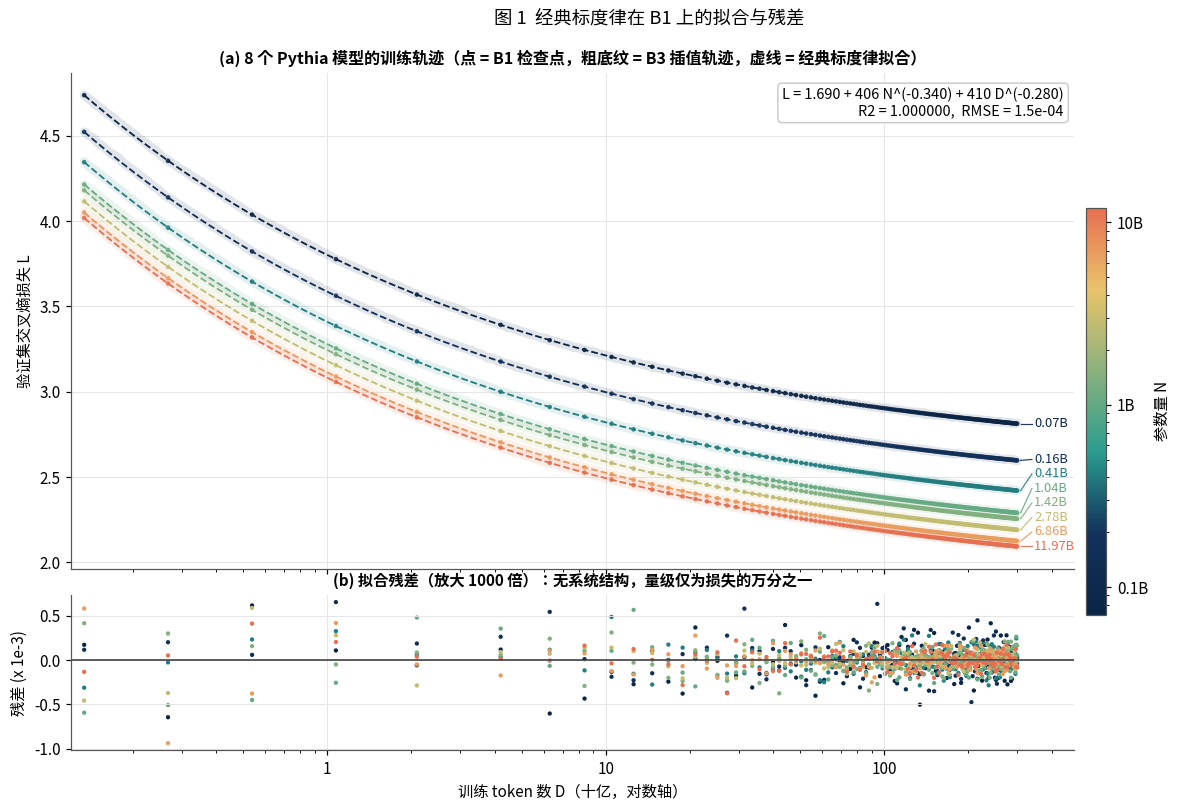

In [3]:
# ============ 1.2 经典标度律拟合（B1 主拟合）+ 留一模型外推检验 ============
def L_classic(N, D, th):
    return th['E'] + th['A'] * np.asarray(N, float) ** (-th['alpha']) + th['B'] * np.asarray(D, float) ** (-th['beta'])

def fit_classic(N, D, L, delta=1e-3):
    N = np.asarray(N, float); D = np.asarray(D, float); L = np.asarray(L, float)
    def pred(x): return np.exp(x[2]) + np.exp(x[0]) * N ** (-x[3]) + np.exp(x[1]) * D ** (-x[4])
    def obj(x):
        r = np.log(pred(x)) - np.log(L)
        return np.where(np.abs(r) < delta, 0.5 * r ** 2, delta * (np.abs(r) - 0.5 * delta)).sum()
    best = None
    for a0, b0, e0, al0, be0 in itertools.product([2, 8, 14], [2, 8, 14], [-0.3, 0.3, 0.9], [0.15, 0.35, 0.6], [0.15, 0.35, 0.6]):
        r = minimize(obj, [a0, b0, e0, al0, be0], method='L-BFGS-B', bounds=[(-5, 30), (-5, 30), (-3, 2), (0.01, 1.5), (0.01, 1.5)])
        if best is None or r.fun < best.fun: best = r
    x = best.x
    return {'E': float(np.exp(x[2])), 'A': float(np.exp(x[0])), 'alpha': float(x[3]), 'B': float(np.exp(x[1])), 'beta': float(x[4]), 'huber': float(best.fun)}

def r2(y, yh): y = np.asarray(y); yh = np.asarray(yh); return 1 - ((y - yh) ** 2).sum() / ((y - y.mean()) ** 2).sum()
def rmse(y, yh): return float(np.sqrt(((np.asarray(y) - np.asarray(yh)) ** 2).mean()))

t0 = time.time(); TH = fit_classic(B1.N, B1.D, B1.val_loss); print('多起点拟合耗时 %.1fs' % (time.time() - t0))
B1['pred'] = L_classic(B1.N, B1.D, TH); B1['res'] = B1.val_loss - B1.pred
print('经典标度律 (B1 主拟合):  E = %.4f  A = %.1f  alpha = %.4f  B = %.1f  beta = %.4f' % (TH['E'], TH['A'], TH['alpha'], TH['B'], TH['beta']))
print('  R2 = %.6f   RMSE = %.5f   最大绝对残差 = %.5f   （残差量级 1e-4：该日志与标度律形式几乎精确一致）' % (r2(B1.val_loss, B1.pred), rmse(B1.val_loss, B1.pred), B1.res.abs().max()))
a_exp, b_exp = TH['beta'] / (TH['alpha'] + TH['beta']), TH['alpha'] / (TH['alpha'] + TH['beta'])
G_const = (TH['alpha'] * TH['A'] / (TH['beta'] * TH['B'])) ** (1 / (TH['alpha'] + TH['beta']))
def N_opt(C): return G_const * (np.asarray(C, float) / 6) ** a_exp
def D_opt(C): return (np.asarray(C, float) / 6) / N_opt(C)
print('计算最优前沿: N* = %.3g (C/6)^%.4f,  D* = (C/6)/N*,  D*/N* 随 C^%.4f 增长' % (G_const, a_exp, (TH['alpha'] - TH['beta']) / (TH['alpha'] + TH['beta'])))
for C in (1e19, 1e22, 1e24):
    print('  C = %.0e FLOPs:  N* = %.3g B 参数,  D* = %.3g B tokens,  D*/N* = %.1f,  L* = %.4f' % (C, N_opt(C) / 1e9, D_opt(C) / 1e9, D_opt(C) / N_opt(C), L_classic(N_opt(C), D_opt(C), TH)))

# 留一模型（leave-one-N-out）外推检验：用其余 7 个模型拟合，预测被留出模型的整条轨迹
jk = []
for n_ in sorted(B1.N.unique()):
    m = B1.N != n_; th = fit_classic(B1.N[m], B1.D[m], B1.val_loss[m]); ph = L_classic(B1.N[~m], B1.D[~m], th)
    jk.append({'留出模型 N (B)': n_ / 1e9, 'alpha': th['alpha'], 'beta': th['beta'], 'E': th['E'], '留出轨迹 RMSE': rmse(B1.val_loss[~m], ph), '终点损失误差': float(ph[-1] - B1.val_loss[~m].iloc[-1])})
JK = pd.DataFrame(jk); print('\n留一模型外推检验（含最小与最大模型的外推）:'); display(JK)
JK.to_csv(TAB / 'classic_law_jackknife.csv', index=False, encoding='utf-8-sig')
pd.Series(TH).to_csv(TAB / 'classic_law_params.csv', encoding='utf-8-sig')

# ---- 图 1：B1 训练轨迹扇面 + 拟合曲线 + 残差带（B3 插值轨迹作底纹） ----
sizes = sorted(B1.N.unique()); norm = mpl.colors.LogNorm(vmin=min(sizes), vmax=max(sizes))
fig = plt.figure(figsize=(14, 8)); gs = gridspec.GridSpec(2, 1, height_ratios=[3.2, 1], hspace=0.08)
ax = fig.add_subplot(gs[0])
Dgrid = np.logspace(np.log10(B1.D.min()), np.log10(B1.D.max()), 300)
for n_ in sizes:
    c = CMAP_SIZE(norm(n_)); g = B1[B1.N == n_]; g3 = B3[np.isclose(B3.N, n_)]
    ax.plot(g3.D / 1e9, g3.val_loss, color=c, lw=6, alpha=0.12, solid_capstyle='round')          # B3 插值轨迹作底纹
    ax.scatter(g.D / 1e9, g.val_loss, s=9, color=c, alpha=0.9, edgecolor='none', zorder=3)
    ax.plot(Dgrid / 1e9, L_classic(n_, Dgrid, TH), color=c, lw=1.2, ls='--', zorder=2)
# 轨迹终点标签：大模型终点损失很接近，做最小间距"排斥"并用细引线连接，避免文字重叠
ends = [(n_, float(B1[B1.N == n_].val_loss.iloc[-1])) for n_ in sizes]; ys = np.array([e[1] for e in ends]); ylab = ys.copy(); order_ = np.argsort(ys); mingap = 0.085
for k in range(1, len(order_)):
    i0, i1 = order_[k - 1], order_[k]
    if ylab[i1] - ylab[i0] < mingap: ylab[i1] = ylab[i0] + mingap
xend = B1.D.max() / 1e9
for (n_, y0), yl in zip(ends, ylab):
    c = CMAP_SIZE(norm(n_)); ax.plot([xend * 1.03, xend * 1.13], [y0, yl], color=c, lw=0.8, alpha=0.9); ax.text(xend * 1.15, yl, '%.2fB' % (n_ / 1e9), color=c, fontsize=8.5, va='center')
ax.set_xscale('log'); ax.xaxis.set_major_formatter(plain); ax.set_xlim(B1.D.min() / 1e9 * 0.9, B1.D.max() / 1e9 * 1.6)
ax.set_ylabel('验证集交叉熵损失 L'); ax.set_title('(a) 8 个 Pythia 模型的训练轨迹（点 = B1 检查点，粗底纹 = B3 插值轨迹，虚线 = 经典标度律拟合）', fontsize=10.5)
ax.text(0.99, 0.97, 'L = %.3f + %.0f N^(-%.3f) + %.0f D^(-%.3f)\nR2 = %.6f,  RMSE = %.1e' % (TH['E'], TH['A'], TH['alpha'], TH['B'], TH['beta'], r2(B1.val_loss, B1.pred), rmse(B1.val_loss, B1.pred)), transform=ax.transAxes, ha='right', va='top', fontsize=9.5, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
ax.tick_params(labelbottom=False)
ax2 = fig.add_subplot(gs[1], sharex=ax)
ax2.scatter(B1.D / 1e9, B1.res * 1e3, s=8, c=[CMAP_SIZE(norm(v)) for v in B1.N], edgecolor='none'); ax2.axhline(0, color='#333333', lw=1)
ax2.set_xscale('log'); ax2.xaxis.set_major_formatter(plain); ax2.set_xlabel('训练 token 数 D（十亿，对数轴）'); ax2.set_ylabel('残差 (x 1e-3)')
ax2.set_title('(b) 拟合残差（放大 1000 倍）：无系统结构，量级仅为损失的万分之一', fontsize=10)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=CMAP_SIZE); cb = fig.colorbar(sm, ax=[ax, ax2], shrink=0.6, pad=0.01, format=mpl.ticker.FuncFormatter(lambda v, _: '%gB' % (v / 1e9))); cb.set_label('参数量 N')
fig.suptitle('图 1  经典标度律在 B1 上的拟合与残差', fontsize=12, y=0.95)
savefig('fig01_b1_trajectories_fit.png'); plt.show()

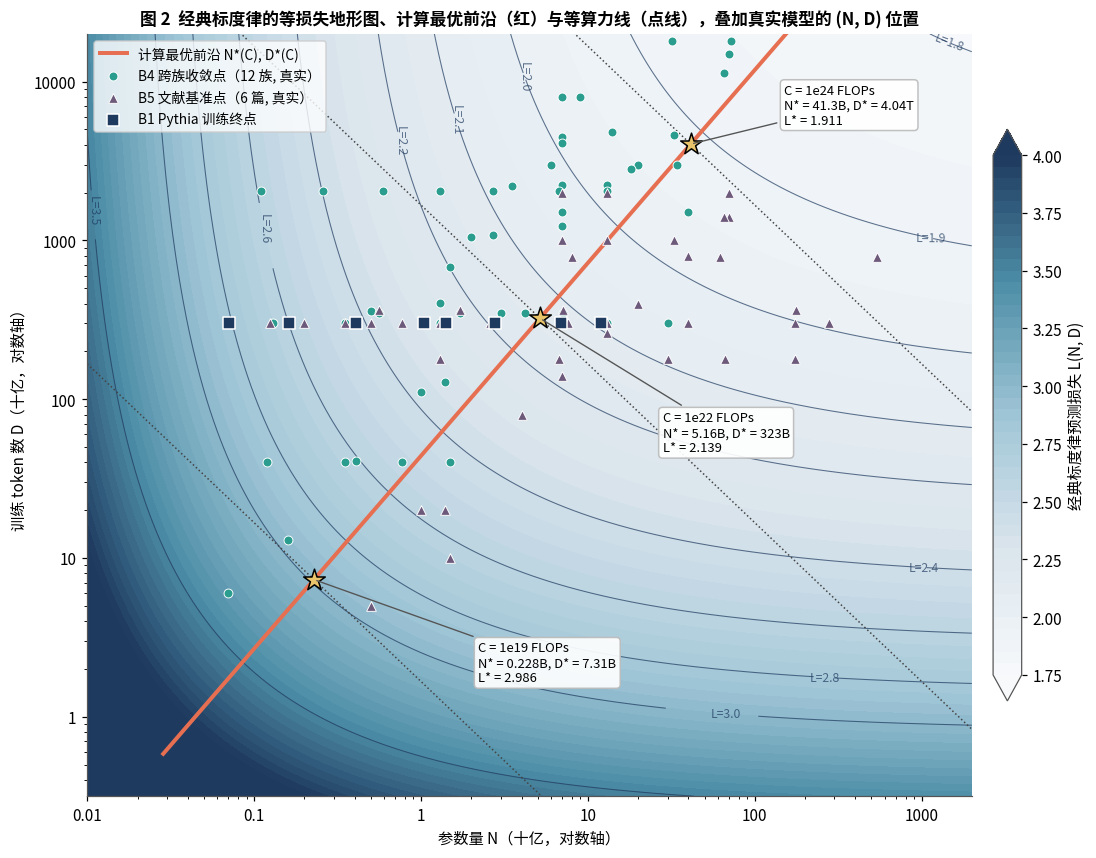

In [4]:
# ---- 图 2：(N, D) 平面上的等损失地形图 + 计算最优前沿 + 等算力线 + 真实模型（B4/B5）散点 ----
Ng = np.logspace(7, 12.3, 260); Dg = np.logspace(8.5, 13.3, 260); NN, DD = np.meshgrid(Ng, Dg)
LL = L_classic(NN, DD, TH)
fig, ax = plt.subplots(figsize=(12.5, 9))
cf = ax.contourf(NN / 1e9, DD / 1e9, LL, levels=np.linspace(1.75, 4.0, 46), cmap=CMAP_TERRAIN, extend='both')
cs = ax.contour(NN / 1e9, DD / 1e9, LL, levels=[1.8, 1.9, 2.0, 2.1, 2.2, 2.4, 2.6, 2.8, 3.0, 3.5], colors='#1F3A5F', linewidths=0.7, alpha=0.7)
ax.clabel(cs, fmt=lambda v: 'L=%.1f' % v, fontsize=8, inline=True)
Cs = np.logspace(17, 27, 200); ax.plot(N_opt(Cs) / 1e9, D_opt(Cs) / 1e9, color=C_CORAL, lw=2.6, label='计算最优前沿 N*(C), D*(C)')
def fmtB(x):                                     # 十亿 -> 'xxB' / 'x.xxT'
    return '%.2fT' % (x / 1000) if x >= 1000 else '%.3gB' % x
for C, lab_, xy_txt in ((1e19, '1e19', (2.2, 1.6)), (1e22, '1e22', (28, 45)), (1e24, '1e24', (150, 5200))):   # 注释框放在无散点的空白区，用引线指向星标
    Nl = np.logspace(7, 12.3, 100); ax.plot(Nl / 1e9, (C / 6 / Nl) / 1e9, color='#444444', lw=1, ls=':')
    ax.scatter([N_opt(C) / 1e9], [D_opt(C) / 1e9], marker='*', s=220, color=C_GOLD, edgecolor='black', zorder=6)
    ax.annotate('C = %s FLOPs\nN* = %s, D* = %s\nL* = %.3f' % (lab_, fmtB(N_opt(C) / 1e9), fmtB(D_opt(C) / 1e9), L_classic(N_opt(C), D_opt(C), TH)), (N_opt(C) / 1e9, D_opt(C) / 1e9), xytext=xy_txt, textcoords='data', fontsize=8.5, ha='left', va='bottom', bbox=dict(boxstyle='round', fc='white', ec='#BBBBBB', alpha=0.92), arrowprops=dict(arrowstyle='-', color='#555555', lw=0.9), zorder=7)
ax.scatter(B4.N_params_B, B4.D_tokens_B, s=34, color=C_TEAL, edgecolor='white', linewidths=0.6, zorder=5, label='B4 跨族收敛点（12 族, 真实）')
ax.scatter(B5.N_params_B, B5.D_tokens_B, s=40, marker='^', color=C_PLUM, edgecolor='white', linewidths=0.6, zorder=5, label='B5 文献基准点（6 篇, 真实）')
ax.scatter(B1.groupby('N').D.max().index / 1e9, B1.groupby('N').D.max().values / 1e9, s=60, marker='s', color=C_NAVY, edgecolor='white', zorder=5, label='B1 Pythia 训练终点')
ax.set_xscale('log'); ax.set_yscale('log'); ax.xaxis.set_major_formatter(plain); ax.yaxis.set_major_formatter(plain)
ax.set_xlim(Ng.min() / 1e9, Ng.max() / 1e9); ax.set_ylim(Dg.min() / 1e9, Dg.max() / 1e9)
ax.set_xlabel('参数量 N（十亿，对数轴）'); ax.set_ylabel('训练 token 数 D（十亿，对数轴）')
cb = plt.colorbar(cf, ax=ax, shrink=0.75, pad=0.02); cb.set_label('经典标度律预测损失 L(N, D)'); ax.grid(False)
ax.legend(loc='upper left', frameon=True, fontsize=9)
ax.set_title('图 2  经典标度律的等损失地形图、计算最优前沿（红）与等算力线（点线），叠加真实模型的 (N, D) 位置', fontsize=11)
savefig('fig02_isoloss_terrain_frontier.png'); plt.show()

## 2. 跨来源验证：可检验假设 H1（指数跨族共享）

附件 A 与 B、以及 B 内部的不同来源（Pythia、Cerebras、12 个开源族、6 篇文献）使用不同的 tokenizer、验证集与训练细节，损失的 **绝对水平** 不可直接比较。要把它们统一进一个模型，需要一个可以被数据否定的假设：

> **H1（指数共享、族级乘子）**：损失对 $N$、$D$ 的幂律指数 $\alpha,\beta$ 是普适的；来源 $f$ 之间的差异只体现为不可约损失的平移 $E_f$ 与可约部分的乘子 $s_f$：
> $$L_f(N,D)=E_f+s_f\,R(N,D),\qquad R(N,D)=A N^{-\alpha}+B D^{-\beta}\ \text{（指数与 } A,B \text{ 取自 B1）}.$$

$s_f$ 的含义是"该来源的数据把可约损失放大或缩小了多少倍"——它与后文的质量乘子 $\psi_Q$、配比乘子 $\psi_p$ 是同一种数学对象，这正是"把不同来源统一到同一模型"的接口。检验分四层：

1. **B2 模型族外验证**：固定 B1 的 $\alpha,\beta$，只对 Cerebras 估计 $(E_f,A_f,B_f)$（线性最小二乘），与完全自由拟合比较：若两者 $R^2$ 与指数几乎相同，则 H1 在族外成立；
2. **B3 插值轨迹验证**：B3 由 B1 插值生成，用 B1 拟合的定律预测 B3 的 4,000 个点；
3. **B4 跨族验证**：嵌套模型比较——(i) 仅偏移 $E_f$，(ii) 偏移 + 乘子 $s_f$，用 $R^2$、AIC 与"族内留一"交叉验证判断乘子是否必要；再用 B4 单独自由拟合指数，展示真实收敛点 **无法单独识别指数**（目标函数平坦）；
4. **B5 文献验证**：同 B4，按文献来源分组；并计算 $R(N,D)$ 与真实损失的 Spearman 秩相关，看定律对真实模型的排序能力。

B2 Cerebras 族外验证:
  共享指数 (alpha=0.340, beta=0.280) + 自估 E,A,B = (1.690, 407.7, 2829.4):  R2 = 0.9995  RMSE = 0.0108
  完全自由拟合:  E=1.680 A=400.0 alpha=0.339 B=2761.3 beta=0.279:  R2 = 0.9995  RMSE = 0.0108
  -> 自由拟合的指数与 B1 仅差 0.001 / 0.001，共享指数模型损失的精度可忽略（Cerebras 的 B 常数约为 Pythia 的 6.9 倍：同一 D 带来的可约损失更大）

B3 插值轨迹验证: 4,000 点 R2 = 0.99996, RMSE = 0.0038, 最大绝对误差 = 0.0147

B4 跨族收敛点（12 组）:
  仅偏移 E_f:        R2 = 0.887  RMSE = 0.1562  AIC = -187.6
  偏移 + 乘子 s_f:   R2 = 0.992  RMSE = 0.0421  AIC = -319.3
  族内留一交叉验证 (n>=4 的组, 49 点): RMSE = 0.0678
  R(N,D) 与真实损失的 Spearman = 0.983

B5 文献基准点（6 组）:
  仅偏移 E_f:        R2 = 0.888  RMSE = 0.1276  AIC = -169.2
  偏移 + 乘子 s_f:   R2 = 0.940  RMSE = 0.0934  AIC = -184.7
  族内留一交叉验证 (n>=4 的组, 41 点): RMSE = 0.1262
  R(N,D) 与真实损失的 Spearman = 0.959

仅用真实收敛点自由拟合指数（不可靠，仅作对照）: B4 -> alpha=0.171 beta=0.428 E=1.309;  B5 -> alpha=0.228 beta=0.113 E=0.050


,来源,n,E_f(仅偏移),E_f(偏移+乘子),s_f,N范围(B),附件
0,BLOOM,4,1.9838,1.5796,1.7645,0.56-7.1,B4
1,Cerebras-GPT,7,1.8757,1.5772,1.5694,0.11-13,B4
2,Falcon,2,1.8480,1.8480,NaN,7-40,B4
3,GPT2,4,1.9011,2.1569,0.7231,0.12-1.5,B4
4,Gemma,3,1.8544,1.6245,1.6710,2-9,B4
5,LLaMA,6,1.7622,1.3947,2.3890,3.5-70,B4
6,Mistral,1,1.8171,1.8171,NaN,7-7,B4
7,OPT,7,1.9708,1.6021,1.6462,0.13-30,B4
8,Phi,6,1.8736,1.6498,1.5920,1.3-18,B4
9,Pythia,8,2.1332,1.5204,1.7581,0.07-12,B4


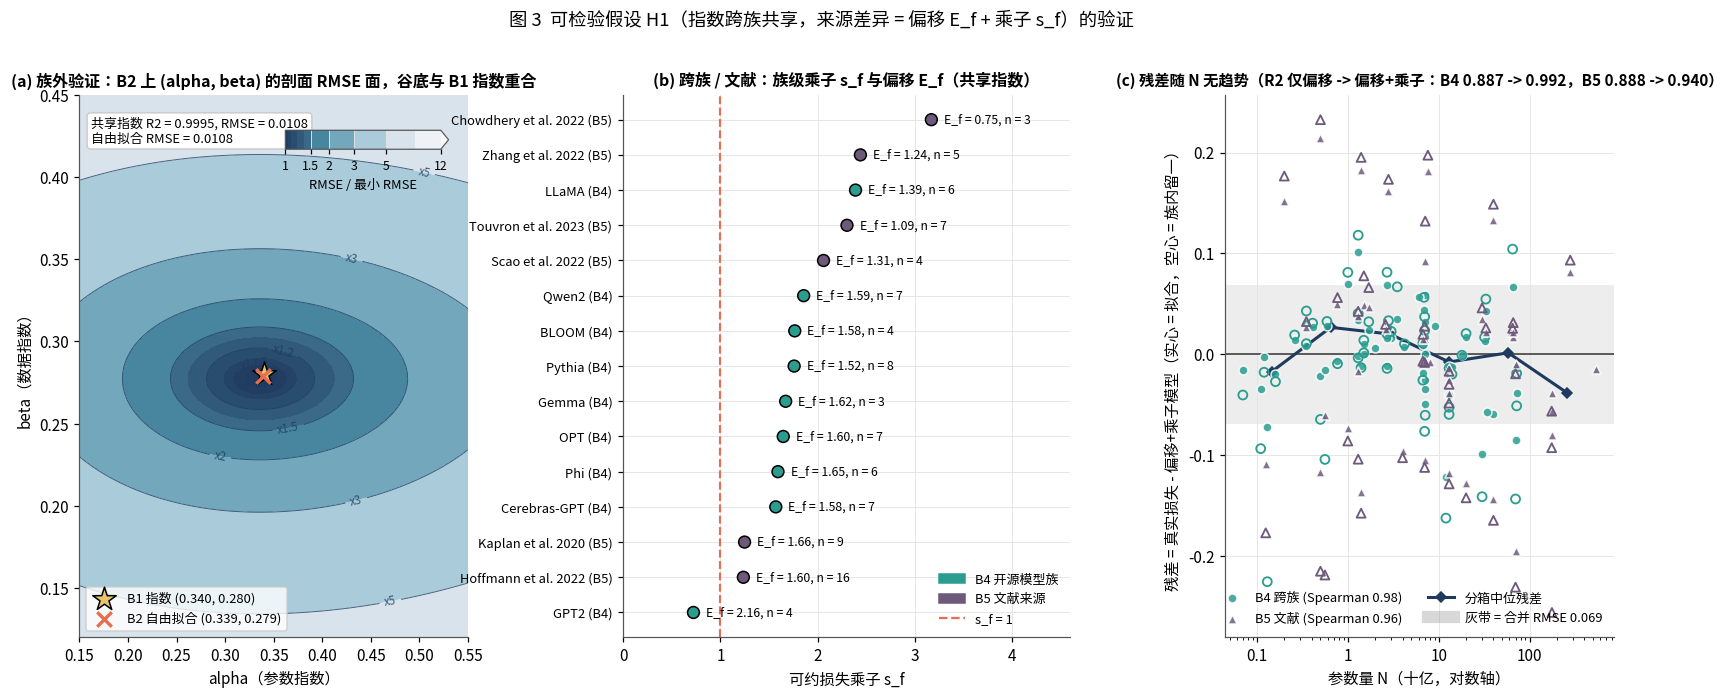

In [5]:
# ============ 2. H1 检验 ============
def R_fun(N, D, th=None):
    th = TH if th is None else th
    return th['A'] * np.asarray(N, float) ** (-th['alpha']) + th['B'] * np.asarray(D, float) ** (-th['beta'])

# (1) B2 族外验证
X2 = np.column_stack([np.ones(len(B2)), B2.N ** (-TH['alpha']), B2.D ** (-TH['beta'])])
coef2, _, _, _ = np.linalg.lstsq(X2, B2.val_loss.values, rcond=None); B2['pred_shared'] = X2 @ coef2
TH2 = fit_classic(B2.N, B2.D, B2.val_loss); B2['pred_free'] = L_classic(B2.N, B2.D, TH2)
print('B2 Cerebras 族外验证:')
print('  共享指数 (alpha=%.3f, beta=%.3f) + 自估 E,A,B = (%.3f, %.1f, %.1f):  R2 = %.4f  RMSE = %.4f' % (TH['alpha'], TH['beta'], coef2[0], coef2[1], coef2[2], r2(B2.val_loss, B2.pred_shared), rmse(B2.val_loss, B2.pred_shared)))
print('  完全自由拟合:  E=%.3f A=%.1f alpha=%.3f B=%.1f beta=%.3f:  R2 = %.4f  RMSE = %.4f' % (TH2['E'], TH2['A'], TH2['alpha'], TH2['B'], TH2['beta'], r2(B2.val_loss, B2.pred_free), rmse(B2.val_loss, B2.pred_free)))
print('  -> 自由拟合的指数与 B1 仅差 %.3f / %.3f，共享指数模型损失的精度可忽略（Cerebras 的 B 常数约为 Pythia 的 %.1f 倍：同一 D 带来的可约损失更大）' % (abs(TH2['alpha'] - TH['alpha']), abs(TH2['beta'] - TH['beta']), coef2[2] / TH['B']))

# (2) B3 插值轨迹验证
B3['pred'] = L_classic(B3.N, B3.D, TH)
print('\nB3 插值轨迹验证: 4,000 点 R2 = %.5f, RMSE = %.4f, 最大绝对误差 = %.4f' % (r2(B3.val_loss, B3.pred), rmse(B3.val_loss, B3.pred), (B3.val_loss - B3.pred).abs().max()))

# (3)(4) B4 / B5 族级模型
def family_models(df, key):
    R = R_fun(df.N, df.D); out = df.copy(); out['R'] = R; rows = []
    out['pred_offset'] = np.nan; out['pred_scale'] = np.nan; out['loo_scale'] = np.nan
    for f, g in out.groupby(key):
        idx = g.index; Ef = (g.val_loss - g.R).mean(); out.loc[idx, 'pred_offset'] = Ef + g.R
        if len(g) >= 3:
            X = np.column_stack([np.ones(len(g)), g.R]); c, _, _, _ = np.linalg.lstsq(X, g.val_loss.values, rcond=None); out.loc[idx, 'pred_scale'] = X @ c; E_s, s_f = c
            if len(g) >= 4:
                for i in idx:
                    gg = g.drop(i); Xg = np.column_stack([np.ones(len(gg)), gg.R]); cc, _, _, _ = np.linalg.lstsq(Xg, gg.val_loss.values, rcond=None)
                    out.loc[i, 'loo_scale'] = cc[0] + cc[1] * out.loc[i, 'R']
        else:
            out.loc[idx, 'pred_scale'] = Ef + g.R; E_s, s_f = Ef, np.nan
        rows.append({'来源': f, 'n': len(g), 'E_f(仅偏移)': Ef, 'E_f(偏移+乘子)': E_s, 's_f': s_f, 'N范围(B)': '%.2g-%.3g' % (g.N_params_B.min(), g.N_params_B.max())})
    return out, pd.DataFrame(rows)
B4m, FAM4 = family_models(B4, 'family'); B5m, FAM5 = family_models(B5, 'source')
def aic(y, yh, k): n = len(y); return n * np.log(((np.asarray(y) - np.asarray(yh)) ** 2).mean()) + 2 * k
for name, dfm, fam, key in (('B4 跨族收敛点', B4m, FAM4, 'family'), ('B5 文献基准点', B5m, FAM5, 'source')):
    k1 = fam.shape[0]; k2 = k1 + fam['s_f'].notna().sum()
    print('\n%s（%d 组）:' % (name, k1))
    print('  仅偏移 E_f:        R2 = %.3f  RMSE = %.4f  AIC = %.1f' % (r2(dfm.val_loss, dfm.pred_offset), rmse(dfm.val_loss, dfm.pred_offset), aic(dfm.val_loss, dfm.pred_offset, k1)))
    print('  偏移 + 乘子 s_f:   R2 = %.3f  RMSE = %.4f  AIC = %.1f' % (r2(dfm.val_loss, dfm.pred_scale), rmse(dfm.val_loss, dfm.pred_scale), aic(dfm.val_loss, dfm.pred_scale, k2)))
    m = dfm.loo_scale.notna(); print('  族内留一交叉验证 (n>=4 的组, %d 点): RMSE = %.4f' % (m.sum(), rmse(dfm.val_loss[m], dfm.loo_scale[m])))
    print('  R(N,D) 与真实损失的 Spearman = %.3f' % stats.spearmanr(dfm.R, dfm.val_loss)[0])
TH4 = fit_classic(B4.N, B4.D, B4.val_loss); TH5 = fit_classic(B5.N, B5.D, B5.val_loss)
print('\n仅用真实收敛点自由拟合指数（不可靠，仅作对照）: B4 -> alpha=%.3f beta=%.3f E=%.3f;  B5 -> alpha=%.3f beta=%.3f E=%.3f' % (TH4['alpha'], TH4['beta'], TH4['E'], TH5['alpha'], TH5['beta'], TH5['E']))
FAM = pd.concat([FAM4.assign(附件='B4'), FAM5.assign(附件='B5')], ignore_index=True); display(FAM)
FAM.to_csv(TAB / 'family_offsets_scales.csv', index=False, encoding='utf-8-sig')

# ---- 图 3：H1 检验三联图 ----
fig = plt.figure(figsize=(18, 6.4)); gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1.15, 1], wspace=0.38)
ax = fig.add_subplot(gs[0])
# (a) 指数剖面：在 (alpha, beta) 网格上，对 B2 用线性最小二乘解 (E, A, B)，得到 RMSE 面——最小点是否落在 B1 的指数上，是 H1 的直接检验
ag = np.linspace(0.15, 0.55, 81); bg = np.linspace(0.12, 0.45, 81); AG, BG = np.meshgrid(ag, bg); RM = np.empty_like(AG)
N2_, D2_, y2_ = B2.N.values, B2.D.values, B2.val_loss.values
for i_ in range(AG.shape[0]):
    for j_ in range(AG.shape[1]):
        X_ = np.column_stack([np.ones(len(y2_)), N2_ ** (-AG[i_, j_]), D2_ ** (-BG[i_, j_])]); c_, _, _, _ = np.linalg.lstsq(X_, y2_, rcond=None); RM[i_, j_] = np.sqrt(((X_ @ c_ - y2_) ** 2).mean())
RMr = RM / RM.min()
cf = ax.contourf(AG, BG, RMr, levels=[1, 1.02, 1.05, 1.1, 1.2, 1.35, 1.5, 2, 3, 5, 8, 12], cmap=CMAP_TERRAIN.reversed(), norm=mpl.colors.LogNorm(vmin=1, vmax=12), extend='max')
cs = ax.contour(AG, BG, RMr, levels=[1.05, 1.2, 1.5, 2, 3, 5], colors='#1F3A5F', linewidths=0.6, alpha=0.8); ax.clabel(cs, fmt=lambda v: 'x%g' % v, fontsize=7.5)
ax.scatter([TH['alpha']], [TH['beta']], marker='*', s=260, color=C_GOLD, edgecolor='black', zorder=6, label='B1 指数 (%.3f, %.3f)' % (TH['alpha'], TH['beta']))
ax.scatter([TH2['alpha']], [TH2['beta']], marker='x', s=90, color=C_CORAL, linewidths=2.2, zorder=6, label='B2 自由拟合 (%.3f, %.3f)' % (TH2['alpha'], TH2['beta']))
ax.set_xlabel('alpha（参数指数）'); ax.set_ylabel('beta（数据指数）'); ax.grid(False); ax.legend(loc='lower left', frameon=True, fontsize=8.5)
cax = ax.inset_axes([0.53, 0.9, 0.42, 0.035]); cb = plt.colorbar(cf, cax=cax, orientation='horizontal', ticks=[1, 1.5, 2, 3, 5, 12], format=plain); cb.set_label('RMSE / 最小 RMSE', fontsize=8.5); cax.tick_params(labelsize=8)
ax.text(0.03, 0.96, '共享指数 R2 = %.4f, RMSE = %.4f\n自由拟合 RMSE = %.4f' % (r2(B2.val_loss, B2.pred_shared), rmse(B2.val_loss, B2.pred_shared), rmse(B2.val_loss, B2.pred_free)), transform=ax.transAxes, va='top', fontsize=8.5, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
ax.set_title('(a) 族外验证：B2 上 (alpha, beta) 的剖面 RMSE 面，谷底与 B1 指数重合', fontsize=10.5)
ax = fig.add_subplot(gs[1])
famp = FAM.dropna(subset=['s_f']).sort_values('s_f'); y = np.arange(len(famp))
ax.scatter(famp['s_f'], y, s=60, color=[C_TEAL if a == 'B4' else C_PLUM for a in famp['附件']], edgecolor='black', zorder=3)
ax.axvline(1, color=C_CORAL, ls='--', lw=1.4, label='s_f = 1（与 Pythia 相同）')
for yi, (_, r) in zip(y, famp.iterrows()):
    ax.text(r['s_f'] + 0.13, yi, 'E_f = %.2f, n = %d' % (r['E_f(偏移+乘子)'], r['n']), va='center', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels([('%s (%s)' % (r['来源'], r['附件'])) for _, r in famp.iterrows()], fontsize=8.5)
ax.set_xlabel('可约损失乘子 s_f'); ax.set_xlim(0, famp['s_f'].max() * 1.45)
ax.legend(handles=[Patch(color=C_TEAL, label='B4 开源模型族'), Patch(color=C_PLUM, label='B5 文献来源'), Line2D([0], [0], color=C_CORAL, ls='--', label='s_f = 1')], frameon=False, fontsize=8.5, loc='lower right')
ax.set_title('(b) 跨族 / 文献：族级乘子 s_f 与偏移 E_f（共享指数）', fontsize=10.5)
ax = fig.add_subplot(gs[2])
# (c) 残差随 N 的分布：若指数随规模漂移，残差会呈现随 N 的系统趋势；空心点为族内留一预测的残差
allres = []
for dfm, c, lab_, mk in ((B4m, C_TEAL, 'B4 跨族 (Spearman %.2f)' % stats.spearmanr(B4m.R, B4m.val_loss)[0], 'o'), (B5m, C_PLUM, 'B5 文献 (Spearman %.2f)' % stats.spearmanr(B5m.R, B5m.val_loss)[0], '^')):
    ax.scatter(dfm.N / 1e9, dfm.val_loss - dfm.pred_scale, s=34, marker=mk, color=c, alpha=0.85, edgecolor='white', label=lab_, zorder=3)
    m = dfm.loo_scale.notna(); ax.scatter(dfm.N[m] / 1e9, dfm.val_loss[m] - dfm.loo_scale[m], s=34, marker=mk, facecolors='none', edgecolors=c, linewidths=1.2, zorder=3)
    allres.append(pd.DataFrame({'N': dfm.N.values, 'r': (dfm.val_loss - dfm.pred_scale).values}))
allres = pd.concat(allres); rm_all = np.sqrt((allres.r ** 2).mean())
ax.axhspan(-rm_all, rm_all, color=C_GREY, alpha=0.18, lw=0); ax.axhline(0, color='#333333', lw=1)
bins_ = np.logspace(np.log10(allres.N.min()) - 0.01, np.log10(allres.N.max()) + 0.01, 7); mid_ = np.sqrt(bins_[1:] * bins_[:-1])
med_ = [allres.r[(allres.N >= lo) & (allres.N < hi)].median() for lo, hi in zip(bins_[:-1], bins_[1:])]
ax.plot(mid_ / 1e9, med_, color=C_NAVY, lw=2, marker='D', ms=5, label='分箱中位残差')
ax.set_xscale('log'); ax.xaxis.set_major_formatter(plain); ax.set_xlabel('参数量 N（十亿，对数轴）'); ax.set_ylabel('残差 = 真实损失 - 偏移+乘子模型（实心 = 拟合，空心 = 族内留一）')
ax.plot([], [], color=C_GREY, lw=8, alpha=0.4, label='灰带 = 合并 RMSE %.3f' % rm_all)
ax.legend(frameon=False, fontsize=8.5, loc='lower right', ncol=2); ax.set_title('(c) 残差随 N 无趋势（R2 仅偏移 -> 偏移+乘子：B4 %.3f -> %.3f，B5 %.3f -> %.3f）' % (r2(B4m.val_loss, B4m.pred_offset), r2(B4m.val_loss, B4m.pred_scale), r2(B5m.val_loss, B5m.pred_offset), r2(B5m.val_loss, B5m.pred_scale)), fontsize=10)
fig.suptitle('图 3  可检验假设 H1（指数跨族共享，来源差异 = 偏移 E_f + 乘子 s_f）的验证', fontsize=12, y=1.0)
savefig('fig03_H1_cross_family.png'); plt.show()

## 3. 质量项：可检验假设 H3 与 B6/B7 上的形式识别

B6–B8 是"基于真实标度律校准并叠加噪声"的半合成 N-D-Q 实验，只能用于识别 **质量进入标度律的函数形式与强度**，不能当作实测证据。识别策略：把 $(E,A,\alpha,B,\beta)$ 固定为 B1 的估计值（B7 中 $Q=1$ 的点相对 B1 定律的残差均值仅约 0.004，说明二者校准一致），只用 B7 估计质量项，对下列候选形式用 AIC 比较：

| 编号 | 形式 | 含义 |
|---|---|---|
| F1 | $E+AN^{-\alpha}+B\,(DQ^{\gamma})^{-\beta}$ | 质量只折损有效数据量 |
| F1b | $E+AN^{-\alpha}+B\,(De^{-k(1-Q)})^{-\beta}$ | 同上，指数型折损 |
| F2 | $E+R(N,D)\,[1+\kappa(1-Q)^{\gamma}]$ | **质量乘在整个可约损失上** |
| F3 | $E+R(N,D)+\kappa(1-Q)^{\gamma}$ | 质量为与规模无关的附加损失 |
| F5 | $E[1+\kappa(1-Q)^\gamma]+R(N,D)$ | 质量抬高不可约损失 |
| F6 | $E+A(NQ^{\gamma_1})^{-\alpha}+B(DQ^{\gamma_2})^{-\beta}$ | 质量同时折损有效 $N$ 与有效 $D$ |

> **H3（质量乘子）**：数据质量以乘子形式作用于可约损失，$L=E+R(N,D)\,\psi_Q(Q)$，$\psi_Q(1)=1$。

若 F2 胜出且 $\gamma\approx1$，则 $\psi_Q(Q)=1+\kappa(1-Q)$，其含义有三层：(i) $Q=1$ 时 **自动退化为经典形式**，这就是赛题要求说明的退化依据——退化不是人为约束，而是 F2 与 B7 数据一致后的推论；(ii) 它等价于有效参数与有效数据同时按 $N_{eff}=N\psi_Q^{-1/\alpha}$、$D_{eff}=D\psi_Q^{-1/\beta}$ 缩水——低质量数据既"读不懂"也"记不住"；(iii) 质量的收益随规模按 $R(N,D)$ 衰减，与 H1 中的族级乘子 $s_f$ 同构。

**B8 的处理**。B8 在每个 $(N,D)$ 单元内损失随 $Q$ **单调上升**，与 B6/B7（100% 的单元内下降）、赛题"教材质量越高越好"的设定以及 $Q\le0.3$ 时损失被截断在 0.5 的异常都矛盾，属于方向反转的不一致数据，本文将其从参数估计中剔除，只在敏感性分析中展示若误用它会得到 $\kappa<0$ 的荒谬结果。

**留出验证**。B7 比 B6 多出 $Q=0.5,0.7$ 两个水平（90 个点）：只用 B6 估计 $\kappa$，预测这 90 个从未见过的质量水平，误差应接近噪声水平（约 0.05）。

**坍缩检验**。乘子形式还有一个不依赖 AIC 的直观判据：把 B7 的每个点按其 $(N,D)$ 单元的 $R(N,D)$ 归一化，$(L-E)/R$ 应只依赖 $Q$、与单元无关——45 个单元的 450 个点会"坍缩"到同一条直线 $1+\kappa(1-Q)$ 上；若质量是附加项（F3），归一化后的点会按 $R$ 的大小张开成扇形。

方向一致性检验:
  B6: 45 个 (N,D) 单元，损失随 Q 下降的单元占 100%，Q 斜率中位数 -0.341
  B7: 45 个 (N,D) 单元，损失随 Q 下降的单元占 100%，Q 斜率中位数 -0.339
  B8(calibrated): 90 个 (N,D) 单元，损失随 Q 下降的单元占 0%，Q 斜率中位数 2.028
  B8(全部): 150 个 (N,D) 单元，损失随 Q 下降的单元占 0%，Q 斜率中位数 1.972
  B8 中 val_loss == 0.5 的截断点数: 364 (21.4%)，且全部出现在 Q <= 0.40
  B7 中 Q=1 的点相对 B1 定律的残差: 均值 0.0036, 标准差 0.0551  -> B7 与 B1 校准一致，噪声水平约 0.055

候选形式比较（(E,A,alpha,B,beta) 固定为 B1 估计，B7 全部 450 点）:

主模型 F2 (gamma = 1): kappa = 0.4600, Bootstrap 95% CI [0.4463, 0.4743];  gamma 自由时的 95% CI [0.909, 1.059] 包含 1
  B7 拟合: R2 = 0.9719, RMSE = 0.0571（噪声水平 0.055）
  留出验证: 仅用 B6 估计 kappa = 0.4597，预测 B7 新增的 Q = [0.5, 0.7] 共 90 点: RMSE = 0.0467, R2 = 0.979
  B8 敏感性: 若误用 B8 全部 / calibrated 部分估计，kappa = -2.812 / -2.488（为负，意味着"质量越高损失越大"，与 B6/B7 及题设矛盾，故剔除）


,形式,参数,RMSE,AIC,dAIC
2,F2 R (1 + k (1-Q)^g),"[0.4578, 0.9879]",0.0571,-2573.2963,0.0000
3,F3 R + k (1-Q)^g,"[0.362, 0.9903]",0.0731,-2350.8385,222.4579
4,F5 E (1 + k (1-Q)^g) + R,"[0.2142, 0.9903]",0.0731,-2350.8385,222.4579
5,"F6 N_eff = N Q^g1, D_eff = D Q^g2","[0.6108, 0.5627]",0.0811,-2257.3716,315.9248
1,F1b D_eff = D exp(-k(1-Q)),[2.3746],0.0987,-2082.2091,491.0873
0,F1 D_eff = D Q^g,[1.0763],0.1147,-1947.0813,626.2150


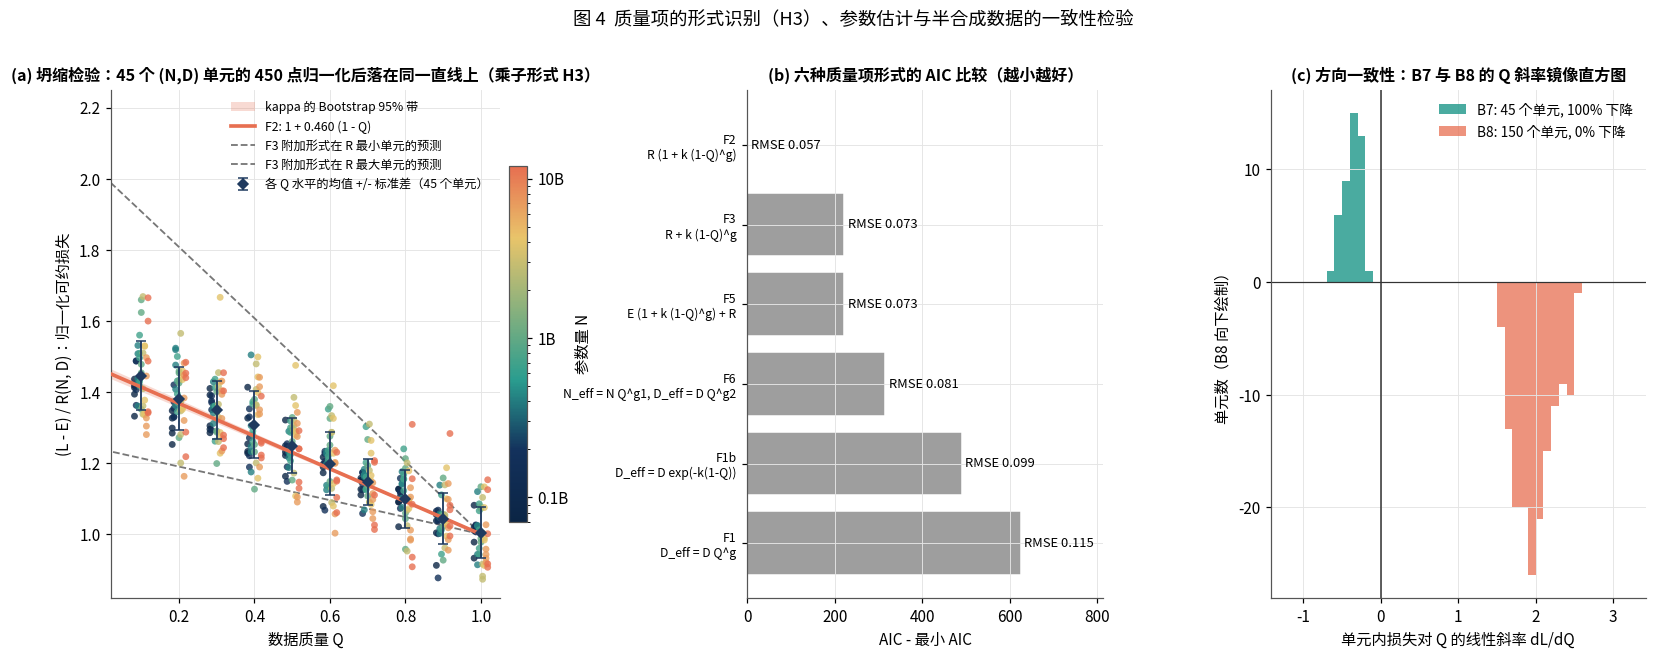

In [6]:
# ============ 3. 质量项形式识别与估计 ============
def slope_sign_table(df, name):
    rows = []
    for (n_, d_), g in df.groupby(['N_params_B', 'D_tokens_B']):
        if g.Q_score.nunique() >= 3:
            sl = np.polyfit(g.Q_score, g.val_loss, 1)[0]; rows.append({'N': n_, 'D': d_, 'slope': sl})
    t = pd.DataFrame(rows); return t, '%s: %d 个 (N,D) 单元，损失随 Q 下降的单元占 %.0f%%，Q 斜率中位数 %.3f' % (name, len(t), 100 * (t.slope < 0).mean(), t.slope.median())
SL6, msg6 = slope_sign_table(B6, 'B6'); SL7, msg7 = slope_sign_table(B7, 'B7'); SL8, msg8 = slope_sign_table(B8[B8.data_type == 'calibrated'], 'B8(calibrated)'); SL8x, msg8x = slope_sign_table(B8, 'B8(全部)')
print('方向一致性检验:'); print(' ', msg6); print(' ', msg7); print(' ', msg8); print(' ', msg8x)
print('  B8 中 val_loss == 0.5 的截断点数: %d (%.1f%%)，且全部出现在 Q <= %.2f' % ((B8.val_loss <= 0.5001).sum(), 100 * (B8.val_loss <= 0.5001).mean(), B8.loc[B8.val_loss <= 0.5001, 'Q_score'].max()))
q1_res = B7.loc[B7.Q_score == 1, 'val_loss'] - L_classic(B7.loc[B7.Q_score == 1, 'N'], B7.loc[B7.Q_score == 1, 'D'], TH)
print('  B7 中 Q=1 的点相对 B1 定律的残差: 均值 %.4f, 标准差 %.4f  -> B7 与 B1 校准一致，噪声水平约 %.3f' % (q1_res.mean(), q1_res.std(), q1_res.std()))

N7, D7, Q7, L7 = B7.N.values, B7.D.values, B7.Q_score.values, B7.val_loss.values
R7 = R_fun(N7, D7); NA7 = TH['A'] * N7 ** (-TH['alpha']); DB7 = TH['B'] * D7 ** (-TH['beta']); Qs = np.maximum(Q7, 1e-6)
FORMS = {
    'F1  D_eff = D Q^g':                  (lambda th, N, D, Q, R, NA, DB: TH['E'] + NA + TH['B'] * (D * np.maximum(Q, 1e-6) ** th[0]) ** (-TH['beta']), [1.0]),
    'F1b D_eff = D exp(-k(1-Q))':         (lambda th, N, D, Q, R, NA, DB: TH['E'] + NA + TH['B'] * (D * np.exp(-th[0] * (1 - Q))) ** (-TH['beta']), [1.0]),
    'F2  R (1 + k (1-Q)^g)':              (lambda th, N, D, Q, R, NA, DB: TH['E'] + R * (1 + th[0] * (1 - Q) ** th[1]), [0.5, 1.0]),
    'F3  R + k (1-Q)^g':                  (lambda th, N, D, Q, R, NA, DB: TH['E'] + R + th[0] * (1 - Q) ** th[1], [0.5, 1.0]),
    'F5  E (1 + k (1-Q)^g) + R':          (lambda th, N, D, Q, R, NA, DB: TH['E'] * (1 + th[0] * (1 - Q) ** th[1]) + R, [0.3, 1.0]),
    'F6  N_eff = N Q^g1, D_eff = D Q^g2': (lambda th, N, D, Q, R, NA, DB: TH['E'] + TH['A'] * (N * np.maximum(Q, 1e-6) ** th[0]) ** (-TH['alpha']) + TH['B'] * (D * np.maximum(Q, 1e-6) ** th[1]) ** (-TH['beta']), [0.5, 0.5])}
rows = []; FITS = {}
for name, (f, x0) in FORMS.items():
    res = least_squares(lambda th: f(th, N7, D7, Q7, R7, NA7, DB7) - L7, x0, method='trf'); r = f(res.x, N7, D7, Q7, R7, NA7, DB7) - L7
    rows.append({'形式': name, '参数': np.round(res.x, 4).tolist(), 'RMSE': np.sqrt((r ** 2).mean()), 'AIC': len(L7) * np.log((r ** 2).mean()) + 2 * len(x0)}); FITS[name] = res.x
FORM_CMP = pd.DataFrame(rows).sort_values('AIC'); FORM_CMP['dAIC'] = FORM_CMP['AIC'] - FORM_CMP['AIC'].min()
print('\n候选形式比较（(E,A,alpha,B,beta) 固定为 B1 估计，B7 全部 450 点）:'); display(FORM_CMP)
FORM_CMP.to_csv(TAB / 'quality_form_comparison.csv', index=False, encoding='utf-8-sig')

# 主模型 F2 且 gamma = 1：kappa 的估计、Bootstrap CI、gamma 的 Bootstrap CI
def fit_kappa(N, D, Q, L, gamma_free=False):
    R = R_fun(N, D)
    if gamma_free:
        res = least_squares(lambda th: TH['E'] + R * (1 + th[0] * (1 - Q) ** th[1]) - L, [0.5, 1.0], method='trf', bounds=([0, 0.2], [5, 5])); return res.x
    X = (R * (1 - Q)).reshape(-1, 1); y = L - TH['E'] - R
    return np.array([float(np.linalg.lstsq(X, y, rcond=None)[0][0])])
KAPPA = fit_kappa(N7, D7, Q7, L7)[0]
boot_k, boot_g = [], []
for b in range(500):
    idx = RNG.integers(0, len(L7), len(L7)); boot_k.append(fit_kappa(N7[idx], D7[idx], Q7[idx], L7[idx])[0]); boot_g.append(fit_kappa(N7[idx], D7[idx], Q7[idx], L7[idx], True)[1])
KAPPA_CI = np.percentile(boot_k, [2.5, 97.5]); GAMMA_CI = np.percentile(boot_g, [2.5, 97.5])
def psi_Q(Q, kappa=None): kappa = KAPPA if kappa is None else kappa; return 1 + kappa * (1 - np.asarray(Q, float))
B7['pred'] = TH['E'] + R7 * psi_Q(Q7)
print('\n主模型 F2 (gamma = 1): kappa = %.4f, Bootstrap 95%% CI [%.4f, %.4f];  gamma 自由时的 95%% CI [%.3f, %.3f] 包含 1' % (KAPPA, KAPPA_CI[0], KAPPA_CI[1], GAMMA_CI[0], GAMMA_CI[1]))
print('  B7 拟合: R2 = %.4f, RMSE = %.4f（噪声水平 %.3f）' % (r2(L7, B7.pred), rmse(L7, B7.pred), q1_res.std()))
# 留出验证：B6 -> B7 新增 Q 水平
k6 = fit_kappa(B6.N.values, B6.D.values, B6.Q_score.values, B6.val_loss.values)[0]
new = B7[~B7.Q_score.isin(B6.Q_score.unique())]; pred_new = TH['E'] + R_fun(new.N, new.D) * psi_Q(new.Q_score, k6)
print('  留出验证: 仅用 B6 估计 kappa = %.4f，预测 B7 新增的 Q = %s 共 %d 点: RMSE = %.4f, R2 = %.3f' % (k6, [float(v) for v in sorted(new.Q_score.unique())], len(new), rmse(new.val_loss, pred_new), r2(new.val_loss, pred_new)))
# B8 敏感性
k8 = fit_kappa(B8.N.values, B8.D.values, B8.Q_score.values, B8.val_loss.values)[0]; k8c = fit_kappa(B8[B8.data_type == 'calibrated'].N.values, B8[B8.data_type == 'calibrated'].D.values, B8[B8.data_type == 'calibrated'].Q_score.values, B8[B8.data_type == 'calibrated'].val_loss.values)[0]
print('  B8 敏感性: 若误用 B8 全部 / calibrated 部分估计，kappa = %.3f / %.3f（为负，意味着"质量越高损失越大"，与 B6/B7 及题设矛盾，故剔除）' % (k8, k8c))
QTERM = {'kappa': KAPPA, 'kappa_ci': KAPPA_CI.tolist(), 'gamma_ci': GAMMA_CI.tolist(), 'kappa_B6_only': k6, 'kappa_B8_misuse': k8}
json.dump(QTERM, open(TAB / 'quality_term.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)

# ---- 图 4：质量项识别三联图 ----
fig = plt.figure(figsize=(18, 6)); gs = gridspec.GridSpec(1, 3, width_ratios=[1.25, 0.95, 1], wspace=0.42)
# (a) 归一化"坍缩图"：若质量以乘子作用于可约损失，则 (L - E) / R(N,D) 只依赖 Q，450 个来自 45 个不同 (N,D) 单元的点应落在同一条直线 1 + kappa (1 - Q) 上；
#     若质量是附加项（F3），归一化后的点会按 R 的大小张开成扇形（灰色虚线给出 R 最小 / 最大单元的 F3 预测）
ax = fig.add_subplot(gs[0]); normN = mpl.colors.LogNorm(vmin=B7.N.min(), vmax=B7.N.max()); ycol = (L7 - TH['E']) / R7
rankN = pd.Series(N7).rank(method='dense').values; jit = (rankN - rankN.mean()) * 0.0045
ax.scatter(Q7 + jit, ycol, s=20, c=[CMAP_SIZE(normN(v)) for v in N7], alpha=0.8, edgecolor='none', zorder=3)
Qg = np.linspace(0, 1, 100); ax.fill_between(Qg, psi_Q(Qg, KAPPA_CI[0]), psi_Q(Qg, KAPPA_CI[1]), color=C_CORAL, alpha=0.25, lw=0, label='kappa 的 Bootstrap 95% 带')
ax.plot(Qg, psi_Q(Qg), color=C_CORAL, lw=2.4, label='F2: 1 + %.3f (1 - Q)' % KAPPA, zorder=4)
thF3 = FITS['F3  R + k (1-Q)^g']
for Rv, lab_ in ((R7.min(), 'F3 附加形式在 R 最小单元的预测'), (R7.max(), 'F3 附加形式在 R 最大单元的预测')):
    ax.plot(Qg, 1 + thF3[0] * (1 - Qg) ** thF3[1] / Rv, color='#777777', lw=1.2, ls='--', label=lab_)
Ql = np.sort(np.unique(Q7)); mQ = [ycol[Q7 == q].mean() for q in Ql]; sQ = [ycol[Q7 == q].std() for q in Ql]
ax.errorbar(Ql, mQ, yerr=sQ, fmt='D', color=C_NAVY, ms=5, capsize=3, lw=1.2, label='各 Q 水平的均值 +/- 标准差（45 个单元）', zorder=5)
ax.set_xlabel('数据质量 Q'); ax.set_ylabel('(L - E) / R(N, D)：归一化可约损失'); ax.set_xlim(0.02, 1.05); ax.set_ylim(0.82, 2.25); ax.legend(frameon=False, fontsize=8, loc='upper right')
sm = mpl.cm.ScalarMappable(norm=normN, cmap=CMAP_SIZE); cb = plt.colorbar(sm, ax=ax, shrink=0.7, pad=0.02, format=mpl.ticker.FuncFormatter(lambda v, _: '%gB' % (v / 1e9))); cb.set_label('参数量 N')
ax.set_title('(a) 坍缩检验：45 个 (N,D) 单元的 450 点归一化后落在同一直线上（乘子形式 H3）', fontsize=10.5)
ax = fig.add_subplot(gs[1]); fc = FORM_CMP.iloc[::-1]
ax.barh(np.arange(len(fc)), fc['dAIC'], color=[C_CORAL if v == 0 else C_GREY for v in fc['dAIC']], edgecolor='white')
for i, (v, rm) in enumerate(zip(fc['dAIC'], fc['RMSE'])): ax.text(v + 8, i, 'RMSE %.3f' % rm, va='center', fontsize=8.5)
ax.set_yticks(np.arange(len(fc))); ax.set_yticklabels([s.split(None, 1)[0] + '\n' + s.split(None, 1)[1] for s in fc['形式']], fontsize=8); ax.set_xlabel('AIC - 最小 AIC'); ax.set_xlim(0, fc['dAIC'].max() * 1.3)
ax.set_title('(b) 六种质量项形式的 AIC 比较（越小越好）', fontsize=10.5)
ax = fig.add_subplot(gs[2]); bins = np.linspace(-1.2, 3.2, 45)
ax.hist(SL7.slope, bins=bins, color=C_TEAL, alpha=0.85, label='B7: %d 个单元, 100%% 下降' % len(SL7))
ax.hist(SL8x.slope, bins=bins, color=C_CORAL, alpha=0.75, label='B8: %d 个单元, %.0f%% 下降' % (len(SL8x), 100 * (SL8x.slope < 0).mean()), weights=-np.ones(len(SL8x)))
ax.axvline(0, color='#333333', lw=1); ax.axhline(0, color='#333333', lw=0.8)
ax.set_xlabel('单元内损失对 Q 的线性斜率 dL/dQ'); ax.set_ylabel('单元数（B8 向下绘制）'); ax.legend(frameon=False, fontsize=9)
ax.set_title('(c) 方向一致性：B7 与 B8 的 Q 斜率镜像直方图', fontsize=10.5)
fig.suptitle('图 4  质量项的形式识别（H3）、参数估计与半合成数据的一致性检验', fontsize=12, y=1.0)
savefig('fig04_quality_term_identification.png'); plt.show()

## 4. 配比项：用问题一的输出引入 $\mathbf p$，可检验假设 H2

问题一在 1M 参数尺度上建立了对数线性混料模型 $\hat L_{mix}(\mathbf p)=c+\sum_i a_i\ln(p_i+\varepsilon)$，并给出了稳健最优配比 $\mathbf p^\star$。要把它嵌入标度律，需要回答：配比造成的损失差异如何随 $N,D$ 变化？

> **H2（配比乘子的尺度不变性）**：配比与质量一样以乘子形式作用于可约损失：
> $$\psi_p(\mathbf p)=\frac{\hat L_{mix}(\mathbf p)-E}{\hat L_{mix}(\mathbf p^\star)-E}\ \ (\ge 1),\qquad L=E+R(N,D)\,\psi_Q(Q)\,\psi_p(\mathbf p),$$
> 即不同配比之间的 **相对** 差距不随规模改变，而 **绝对** 差距随 $R(N,D)$ 一起衰减。RegMix 与 Pythia 共用 The Pile 验证语料，故不可约损失取同一个 $E$。

这一假设可以用问题一保存的各尺度统计量检验：若 H2 成立，则对任意尺度 $s$，
$$\frac{\mathrm{std}_s(L)}{\overline{L}_s-E}=\frac{\mathrm{std}(\psi_p)}{\overline{\psi_p}}=\mathrm{CV}_\psi$$
应为与尺度无关的常数；而"配比效应为附加常数"的对立假设（$L=E+R+\Delta(\mathbf p)$）预测 $\mathrm{std}_s(L)$ 在 1M、60M、1B 三个尺度上保持不变。前者由 $\mathbf p$ 的分布决定，可以直接用问题一的 512 组训练配比算出 $\mathrm{CV}_\psi$ 作预测值。两种假设在 $\ln\mathrm{std}_s$–$\ln(\overline L_s-E)$ 平面上分别对应斜率 1 与斜率 0 的直线，三个尺度的点落在哪条线附近即为判据。此外，广义标度律把 $\psi_Q$ 与 $\psi_p$ 写成 **可分离的乘积**，其前提是二者携带不同的信息：若配比乘子 $\psi_p(\mathbf p)$ 能被配比级质量 $\bar Q(\mathbf p)=\sum_i p_iQ_i$ 解释，则应把 $\mathbf p$ 的作用并入 $Q$；下面用 512 组训练配比检验二者的秩相关。$\mathbf p^\star=\mathbf p^{rob}$ 时 $\psi_p=1$，广义标度律退化为只含质量项的形式；$Q=1$ 且 $\mathbf p=\mathbf p^\star$ 时退化为经典形式。

问题一接口: 稳健最优配比 p* 的 1M 尺度预测损失 4.3624，均匀配比 4.4069 -> psi_p(均匀) = 1.0166
512 组训练配比的 psi_p: 均值 1.368, 标准差 0.112, 范围 [1.086, 1.652], CV_psi = 0.0821

H2 检验：配比造成的损失离散随尺度的变化（E 取 1.690）
相对离散在 1M/60M/1B 上的极差 / 均值 = 0.28；绝对 std 从 1M 到 1B 缩小 5.3 倍，而可约部分缩小 6.7 倍
log(std) 对 log(mean - E) 的拟合斜率 = 0.91（H2 乘子假设预测 1，附加常数假设预测 0）
512 组训练配比的 psi_p 与配比级质量 Qbar 的 Spearman = -0.004（|rho| 小 -> 配比乘子与质量乘子携带不同信息，支持可分离的乘积形式）
  |Qbar - 中位数| 与 psi_p 的 Spearman = 0.068（偏离中间质量的极端配比更差）；Qbar 处于中间 20% 分位的配比，psi_p 仍跨越 [1.152, 1.652] -> 质量不能替代配比


,尺度,N_params,n,平均损失,观测 std,可约部分 mean-E,相对离散 std/(mean-E),H2 预测 std = CV_psi*(mean-E),附加常数假设预测 std
0,1M 训练集,1000000.0000,512,5.3447,0.3245,3.6548,0.0888,0.3002,0.2777
1,1M,1000000.0000,256,5.2823,0.2777,3.5924,0.0773,0.2951,0.2777
2,60M,60000000.0000,256,3.8229,0.2189,2.1331,0.1026,0.1752,0.2777
3,1B,1000000000.0000,64,2.2256,0.0519,0.5357,0.0970,0.0440,0.2777


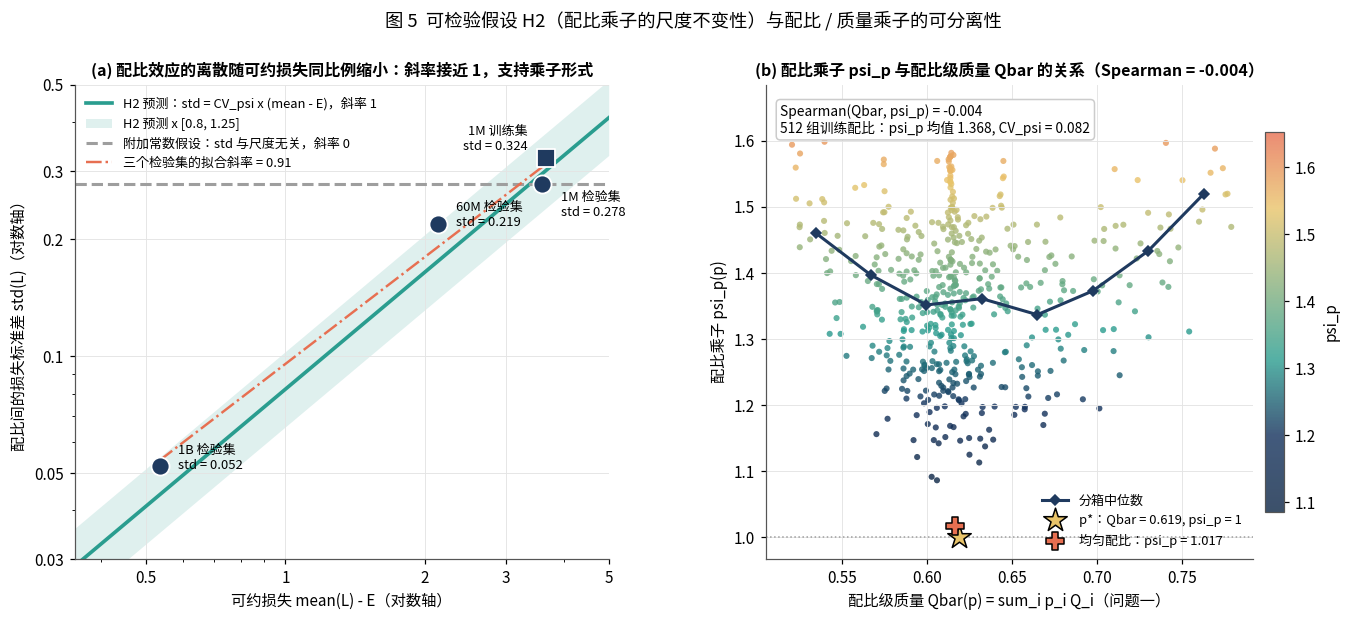

In [7]:
# ============ 4. 配比乘子与 H2 检验 ============
DOM17 = Q1['domain_order']; A_LOG = np.array([Q1['log_linear_model']['a_i'][d] for d in DOM17]); C0 = Q1['log_linear_model']['intercept']; EPS_LOG = Q1['log_linear_model']['epsilon']
P_STAR = np.array([Q1['p_star'][d] for d in DOM17]); Q17 = pd.Series({d: Q1['mixture_domain_Q'][d] for d in DOM17}); Q_BAR = float(Q1['Qbar_p_star'])
def L_mix(p): p = np.asarray(p, float); return C0 + (A_LOG * np.log(p + EPS_LOG)).sum(axis=-1)
L_STAR = float(L_mix(P_STAR)); E0 = TH['E']
def psi_p(p): return (L_mix(p) - E0) / (L_STAR - E0)
uniform = np.ones(17) / 17
print('问题一接口: 稳健最优配比 p* 的 1M 尺度预测损失 %.4f，均匀配比 %.4f -> psi_p(均匀) = %.4f' % (L_STAR, L_mix(uniform), psi_p(uniform)))
Lhat_tr = np.array(Q1['train_mixture_loss_hat']); psi_tr = (Lhat_tr - E0) / (L_STAR - E0)
CV_psi = psi_tr.std() / psi_tr.mean()
print('512 组训练配比的 psi_p: 均值 %.3f, 标准差 %.3f, 范围 [%.3f, %.3f], CV_psi = %.4f' % (psi_tr.mean(), psi_tr.std(), psi_tr.min(), psi_tr.max(), CV_psi))
SS = Q1['regmix_scale_stats']; rows = []
for k in ['1M 训练集', '1M', '60M', '1B']:
    s = SS[k]; rows.append({'尺度': k, 'N_params': s['N_params'], 'n': s['n'], '平均损失': s['mean'], '观测 std': s['std'], '可约部分 mean-E': s['mean'] - E0,
                            '相对离散 std/(mean-E)': s['std'] / (s['mean'] - E0), 'H2 预测 std = CV_psi*(mean-E)': CV_psi * (s['mean'] - E0), '附加常数假设预测 std': SS['1M']['std']})
H2 = pd.DataFrame(rows); print('\nH2 检验：配比造成的损失离散随尺度的变化（E 取 %.3f）' % E0); display(H2)
print('相对离散在 1M/60M/1B 上的极差 / 均值 = %.2f；绝对 std 从 1M 到 1B 缩小 %.1f 倍，而可约部分缩小 %.1f 倍' % ((H2['相对离散 std/(mean-E)'].max() - H2['相对离散 std/(mean-E)'].min()) / H2['相对离散 std/(mean-E)'].mean(), SS['1M']['std'] / SS['1B']['std'], (SS['1M']['mean'] - E0) / (SS['1B']['mean'] - E0)))
H2.to_csv(TAB / 'H2_scale_invariance_test.csv', index=False, encoding='utf-8-sig')

# 斜率检验：log(std) 对 log(mean - E) 的斜率，H2 预测 1（乘子），附加常数假设预测 0
h = H2[H2['尺度'] != '1M 训练集']; xs_ = np.log(h['可约部分 mean-E'].values); ys_ = np.log(h['观测 std'].values); slope_H2 = np.polyfit(xs_, ys_, 1)[0]
print('log(std) 对 log(mean - E) 的拟合斜率 = %.2f（H2 乘子假设预测 1，附加常数假设预测 0）' % slope_H2)
# 配比乘子与配比级质量的关系：二者是否携带不同信息（可分离性）
Qbar_tr = np.array(Q1['train_mixture_Qbar']); rho_pq = stats.spearmanr(Qbar_tr, psi_tr)[0]
print('512 组训练配比的 psi_p 与配比级质量 Qbar 的 Spearman = %.3f（|rho| 小 -> 配比乘子与质量乘子携带不同信息，支持可分离的乘积形式）' % rho_pq)
rho_u = stats.spearmanr(np.abs(Qbar_tr - np.median(Qbar_tr)), psi_tr)[0]; qmid = (Qbar_tr > np.percentile(Qbar_tr, 40)) & (Qbar_tr < np.percentile(Qbar_tr, 60))
print('  |Qbar - 中位数| 与 psi_p 的 Spearman = %.3f（偏离中间质量的极端配比更差）；Qbar 处于中间 20%% 分位的配比，psi_p 仍跨越 [%.3f, %.3f] -> 质量不能替代配比' % (rho_u, psi_tr[qmid].min(), psi_tr[qmid].max()))

# ---- 图 5：H2 检验（对数-对数斜率图）+ 配比乘子与质量的可分离性 ----
fig = plt.figure(figsize=(15, 5.6)); gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.1], wspace=0.28)
ax = fig.add_subplot(gs[0])
xx = np.linspace(0.3, 5, 100)
ax.plot(xx, CV_psi * xx, color=C_TEAL, lw=2.4, label='H2 预测：std = CV_psi x (mean - E)，斜率 1')
ax.fill_between(xx, 0.8 * CV_psi * xx, 1.25 * CV_psi * xx, color=C_TEAL, alpha=0.15, lw=0, label='H2 预测 x [0.8, 1.25]')
ax.axhline(SS['1M']['std'], color=C_GREY, lw=2, ls='--', label='附加常数假设：std 与尺度无关，斜率 0')
lab_scale = {'1M 训练集': '1M 训练集', '1M': '1M 检验集', '60M': '60M 检验集', '1B': '1B 检验集'}
for r in H2.itertuples():
    mk = 's' if r[1] == '1M 训练集' else 'o'; ax.scatter(r[6], r[5], s=140, marker=mk, color=C_NAVY, edgecolor='white', linewidths=1.2, zorder=5)
    off_ = {'1M 训练集': (-12, 12, 'right'), '1M': (12, -14, 'left'), '60M': (12, 6, 'left'), '1B': (12, 6, 'left')}[r[1]]
    ax.annotate('%s\nstd = %.3f' % (lab_scale[r[1]], r[5]), (r[6], r[5]), xytext=off_[:2], textcoords='offset points', fontsize=8.5, ha=off_[2], va='center')
ax.plot(np.exp(xs_), np.exp(np.polyval(np.polyfit(xs_, ys_, 1), xs_)), color=C_CORAL, lw=1.6, ls='-.', label='三个检验集的拟合斜率 = %.2f' % slope_H2)
ax.set_xscale('log'); ax.set_yscale('log'); ax.xaxis.set_major_formatter(plain); ax.yaxis.set_major_formatter(plain)
ax.set_xlim(0.35, 5); ax.set_ylim(0.03, 0.5); ax.set_xticks([0.5, 1, 2, 3, 5]); ax.set_yticks([0.03, 0.05, 0.1, 0.2, 0.3, 0.5]); ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter()); ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel('可约损失 mean(L) - E（对数轴）'); ax.set_ylabel('配比间的损失标准差 std(L)（对数轴）')
ax.legend(frameon=False, fontsize=8.5, loc='upper left'); ax.set_title('(a) 配比效应的离散随可约损失同比例缩小：斜率接近 1，支持乘子形式', fontsize=10.5)
ax = fig.add_subplot(gs[1])
sc = ax.scatter(Qbar_tr, psi_tr, s=16, c=psi_tr, cmap=CMAP_SIZE, alpha=0.8, edgecolor='none')
qb_ = np.linspace(Qbar_tr.min(), Qbar_tr.max(), 9); mid_ = 0.5 * (qb_[1:] + qb_[:-1]); med_ = [np.median(psi_tr[(Qbar_tr >= lo) & (Qbar_tr < hi)]) if ((Qbar_tr >= lo) & (Qbar_tr < hi)).sum() >= 5 else np.nan for lo, hi in zip(qb_[:-1], qb_[1:])]
ax.plot(mid_, med_, color=C_NAVY, lw=2, marker='D', ms=5, label='分箱中位数')
ax.scatter([Q_BAR], [1.0], marker='*', s=260, color=C_GOLD, edgecolor='black', zorder=6, label='p*：Qbar = %.3f, psi_p = 1' % Q_BAR)
ax.scatter([float(uniform @ Q17.values)], [float(psi_p(uniform))], marker='P', s=140, color=C_CORAL, edgecolor='black', zorder=6, label='均匀配比：psi_p = %.3f' % psi_p(uniform))
ax.axhline(1, color=C_GREY, lw=1, ls=':'); ax.set_xlabel('配比级质量 Qbar(p) = sum_i p_i Q_i（问题一）'); ax.set_ylabel('配比乘子 psi_p(p)')
ax.text(0.03, 0.96, 'Spearman(Qbar, psi_p) = %.3f\n512 组训练配比：psi_p 均值 %.3f, CV_psi = %.3f' % (rho_pq, psi_tr.mean(), CV_psi), transform=ax.transAxes, va='top', fontsize=9, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
cb = plt.colorbar(sc, ax=ax, shrink=0.8, pad=0.02, format=plain); cb.set_label('psi_p'); ax.legend(frameon=False, fontsize=8.5, loc='lower right')
ax.set_title('(b) 配比乘子 psi_p 与配比级质量 Qbar 的关系（Spearman = %.3f）' % rho_pq, fontsize=10.5)
fig.suptitle('图 5  可检验假设 H2（配比乘子的尺度不变性）与配比 / 质量乘子的可分离性', fontsize=12, y=1.0)
savefig('fig05_H2_mixture_multiplier.png'); plt.show()

## 5. 广义标度律：合成、边际效用与弹性、替代关系

### 5.1 广义标度律

综合 H1–H3，得到同时包含 $N,D,Q,\mathbf p$ 的广义标度律
$$\boxed{\,L(N,D,Q,\mathbf p)=E+\big(AN^{-\alpha}+BD^{-\beta}\big)\,\big[1+\kappa(1-Q)\big]\,\psi_p(\mathbf p)\,}$$
其中 $E,A,\alpha,B,\beta$ 由 B1 估计，$\kappa$ 由 B7 估计（半合成，附 Bootstrap 区间），$\psi_p$ 由问题一的混料模型给出。性质：(i) $Q=1,\ \mathbf p=\mathbf p^\star$ 时退化为经典形式；(ii) 三个乘子可分离，$N$–$D$ 的最优分配（计算最优前沿）**不随 $Q,\mathbf p$ 改变**——质量与配比只改变损失水平和"每单位算力的回报"，这也是问题三中质量只有在有成本时才会与 $N,D$ 竞争预算的原因；(iii) 等价有效规模 $N_{eff}=N(\psi_Q\psi_p)^{-1/\alpha}$、$D_{eff}=D(\psi_Q\psi_p)^{-1/\beta}$。

### 5.2 边际效用与弹性

记 $\Psi=\psi_Q\psi_p$。各因素的边际效用（损失下降量）与弹性（损失的对数对因素对数的导数）为
$$-\frac{\partial L}{\partial N}=\alpha A N^{-\alpha-1}\Psi,\quad -\frac{\partial L}{\partial D}=\beta B D^{-\beta-1}\Psi,\quad -\frac{\partial L}{\partial Q}=\kappa R(N,D)\psi_p,$$
$$\varepsilon_N=\frac{\partial\ln L}{\partial\ln N}=-\frac{\alpha AN^{-\alpha}\Psi}{L},\quad \varepsilon_D=-\frac{\beta BD^{-\beta}\Psi}{L},\quad \varepsilon_Q=\frac{\partial\ln L}{\partial\ln Q}=-\frac{\kappa Q\,R(N,D)\,\psi_p}{L}.$$
三者皆为负（因素增加、损失下降），其相对大小回答"同样多的相对投入用在哪里更划算"。一个有用的解析结果：在计算最优前沿上 $\alpha AN^{-\alpha}=\beta BD^{-\beta}$，因此 $|\varepsilon_N|=|\varepsilon_D|$，且三者的 **份额** $|\varepsilon_N|:|\varepsilon_D|:|\varepsilon_Q|=\frac{\alpha\beta}{\alpha+\beta}:\frac{\alpha\beta}{\alpha+\beta}:\frac{\kappa Q}{\psi_Q(Q)}$ **与算力 $C$ 无关、只随 $Q$ 变化**——这是乘子形式的直接推论，也意味着"质量的相对重要性"不会随规模消失。**单位算力的回报** 还要除以边际成本：$N$ 与 $D$ 的边际算力成本分别为 $6D$、$6N$；质量的边际算力成本由赛题附录 B 的成本函数 $C_Q=D\,[g(Q)-g(Q_0)]_+$ 给出，$\partial C_Q/\partial Q=D\,g'(Q)$（指数型 $g'=\gamma\lambda e^{\lambda Q}$，幂函数型 $g'=\gamma\lambda Q^{\lambda-1}$，对数型 $g'=\gamma\lambda/(1+\lambda Q)$）。于是"同样多花一块钱（1 FLOP）"的回报比为
$$\rho(N,D,Q)=\frac{-\partial L/\partial Q\,/\,(D g'(Q))}{-\partial L/\partial N\,/\,(6D)}=\frac{6\kappa R(N,D)}{g'(Q)\,\alpha AN^{-\alpha-1}\,\psi_Q(Q)},$$
$D$ 与 $\psi_p$ 都约掉了：$\rho>1$ 时买好教材更划算，$\rho=1$ 是盈亏平衡线。本节把 $\rho$ 画成 $(C,Q)$ 平面上的决策地图，为问题三提供直觉。

### 5.3 质量与规模的替代条件

在 $D,\mathbf p$ 不变时，"质量从 $Q$ 提升到 $Q+\Delta Q$"与"参数从 $N$ 增加到 $N'$"等价，当且仅当损失相等：
$$R(N',D)\,\psi_Q(Q)=R(N,D)\,\psi_Q(Q+\Delta Q)\ \Longrightarrow\
N'=\Bigg[\frac{1}{A}\Big(R(N,D)\frac{\psi_Q(Q+\Delta Q)}{\psi_Q(Q)}-BD^{-\beta}\Big)\Bigg]^{-1/\alpha}.$$
这就是"质量提升 0.1 等价于参数增加多少"的 **可计算条件**：等价参数倍数 $M=N'/N$ 只依赖 $(N,D,Q,\Delta Q)$ 与已估参数。整理可得 $M=\big[r+\rho_{ND}(r-1)\big]^{-1/\alpha}$，其中 $r=\psi_Q(Q+\Delta Q)/\psi_Q(Q)<1$，$\rho_{ND}=BD^{-\beta}/(AN^{-\alpha})$ 是数据项与参数项之比：$M$ 只通过 $\rho_{ND}$ 依赖规模，数据越充裕（$\rho_{ND}$ 越小）质量越"值钱"；在计算最优前沿上 $\rho_{ND}=\alpha/\beta$ 为常数，因此 **沿前沿的等价倍数与算力无关**。反向地，"参数翻倍"等价的质量提升为 $\Delta Q_{eq}=\big[\psi_Q(Q)-\psi_Q(Q)R(2N,D)/R(N,D)\big]/\kappa$。可替代的 **存在条件** 是括号内为正：$R(N,D)\psi_Q(Q+\Delta Q)/\psi_Q(Q)>BD^{-\beta}$，即质量提升带来的损失下降不能超过参数项 $AN^{-\alpha}$ 能贡献的全部——当 $N$ 已经很大、参数项几乎耗尽时，再多的参数也换不来 $0.1$ 的质量提升，此时质量是"不可替代"的。用弹性表述，同样的一阶近似为 $\Delta\ln N\approx(\varepsilon_Q/\varepsilon_N)\,\Delta Q/Q$。

### 5.4 领域数据之间的替代与互补

配比只通过 $\psi_p$ 进入，因此领域间关系由问题一的混料模型决定。在配比 $\mathbf p$ 处，域 $i$ 与域 $k$ 的 **边际替代率**（保持损失不变、用域 $k$ 的份额替换域 $i$ 的份额的交换比）为
$$\mathrm{MRS}_{ik}=\frac{\partial \hat L_{mix}/\partial p_i}{\partial \hat L_{mix}/\partial p_k}=\frac{a_i/(p_i+\varepsilon)}{a_k/(p_k+\varepsilon)},$$
$\mathrm{MRS}_{ik}>1$ 表示一单位域 $i$ 的数据比一单位域 $k$ 的数据更"值钱"；在最优配比 $\mathbf p^\star$ 处所有内点域的 MRS 等于 1（KKT 条件）。**互补 / 替代** 由问题一对数二阶模型的交互系数 $b_{ik}$ 判定：$b_{ik}<0$ 为互补（同时增加两域的收益超过各自之和），$b_{ik}>0$ 为替代。下面在均匀配比处计算 17×17 的 MRS 矩阵（存表），并用两种方式展示：环形网络图（边 = 互补 / 替代关系，圆面积 = 边际价值，颜色 = 问题一的领域质量）与"边际价值阶梯"（对数轴上两域的高度差就是 $\ln\mathrm{MRS}$）。

参考点处的弹性与单位算力回报（Q = 0.619 为问题一 p* 的配比级质量；每 FLOP 的损失下降取 log10）:

质量-规模替代（D 不变）:
解析：N'/N 只依赖比值 B D^-beta / (A N^-alpha)，在计算最优前沿上该比值恒为 alpha/beta，故 dQ = 0.1 的等价参数倍数沿前沿为常数 = 1.306（与 C 无关）；替代存在条件在前沿上恒成立（beta/alpha (psi'/psi - 1) + psi'/psi = 0.913 > 0）

均匀配比处的边际价值 a_i/(p_i+eps)（越负越值钱）:
stackexchange       -0.9390
dm_mathematics      -0.9250
pile_cc             -0.8080
ubuntu_irc          -0.7780
pubmed_central      -0.6360
github              -0.5370
arxiv               -0.5040
wikipedia_en        -0.4960
freelaw             -0.4660
pubmed_abstracts    -0.3820
uspto_backgrounds   -0.3750
hackernews          -0.3480
gutenberg_pg_19     -0.2380
enron_emails        -0.1430
philpapers          -0.1290
nih_exporter        -0.0820
europarl            -0.0010

沿前沿的弹性份额（解析）: |eps_N| : |eps_D| : |eps_Q| = 0.154 : 0.154 : kappa Q / psi_Q(Q)  -> 与 C 无关；Q = 0.62 时质量份额 = 0.441, Q = 1 时 = 0.600
  指数型 g = 1e7 exp(6Q): 前沿上 C=1e19/1e22/1e24 处、Q=0.62 的回报比 = 1.42 / 32.08 / 256.62
  幂函数型 g = 5e9 Q^4: 前沿上 C=1e19

,参考点,N(B),D(B),Q,L,eps_N,eps_D,eps_Q,log10 每FLOP下降(N),log10 每FLOP下降(D),"log10 每FLOP下降(Q,指数型)","log10 每FLOP下降(Q,幂函数型)","log10 每FLOP下降(Q,对数渐进型)"
0,Pythia-1B @ 300B tokens,1.0400,300.0000,1.0000,2.2904,-0.0518,-0.0307,-0.1206,-22.1977,-22.4251,-22.4197,-22.3369,-21.2955
1,Pythia-1B @ 300B tokens,1.0400,300.0000,0.8000,2.3457,-0.0553,-0.0327,-0.0942,-22.1595,-22.3869,-21.8986,-22.0461,-21.3826
2,Pythia-1B @ 300B tokens,1.0400,300.0000,0.6189,2.3957,-0.0583,-0.0345,-0.0714,-22.1275,-22.3550,-21.4267,-21.7117,-21.4802
3,计算最优 @ C=1e22,5.1587,323.0779,1.0000,2.1386,-0.0322,-0.0322,-0.0965,-23.1618,-23.1618,-22.5785,-22.4956,-21.4542
4,计算最优 @ C=1e22,5.1587,323.0779,0.8000,2.1799,-0.0345,-0.0345,-0.0758,-23.1236,-23.1236,-22.0573,-22.2048,-21.5413
5,计算最优 @ C=1e22,5.1587,323.0779,0.6189,2.2173,-0.0365,-0.0365,-0.0576,-23.0917,-23.0917,-21.5854,-21.8705,-21.6389
6,LLaMA-7B @ 1T tokens,7.0000,1000.0000,1.0000,2.0519,-0.0303,-0.0245,-0.0812,-23.8301,-23.9224,-23.1624,-23.0795,-22.0381
7,LLaMA-7B @ 1T tokens,7.0000,1000.0000,0.8000,2.0852,-0.0325,-0.0263,-0.0639,-23.7919,-23.8842,-22.6412,-22.7888,-22.1253
8,LLaMA-7B @ 1T tokens,7.0000,1000.0000,0.6189,2.1154,-0.0345,-0.0279,-0.0487,-23.7600,-23.8523,-22.1694,-22.4544,-22.2228
9,计算最优 @ C=1e24,41.2667,4038.7718,1.0000,1.9111,-0.0178,-0.0178,-0.0533,-25.4689,-25.4689,-23.9824,-23.8995,-22.8582


,参考点,Q,等价参数倍数 N'/N (dQ=0.1),参数翻倍等价的 dQ,条件 R psi(Q+0.1)/psi(Q) > B D^-beta
0,Pythia-1B @ 300B tokens,0.5000,1.2159,0.3265,True
1,Pythia-1B @ 300B tokens,0.7000,1.2360,0.3021,True
2,Pythia-1B @ 300B tokens,0.9000,1.2602,0.2777,True
3,计算最优 @ C=1e22,0.5000,1.2895,0.2535,True
4,计算最优 @ C=1e22,0.7000,1.3176,0.2345,True
5,计算最优 @ C=1e22,0.9000,1.3517,0.2156,True
6,LLaMA-7B @ 1T tokens,0.5000,1.2542,0.2832,True
7,LLaMA-7B @ 1T tokens,0.7000,1.2784,0.2620,True
8,LLaMA-7B @ 1T tokens,0.9000,1.3077,0.2409,True
9,计算最优 @ C=1e24,0.5000,1.2895,0.2535,True


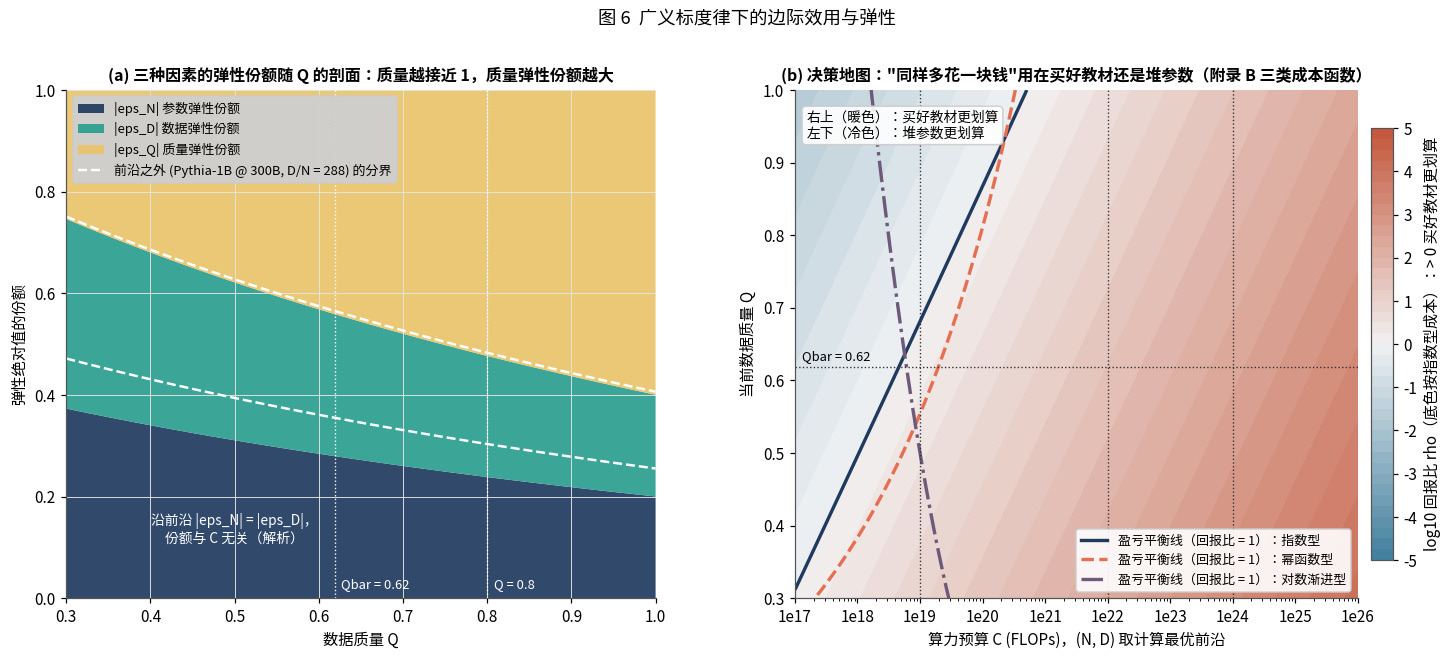

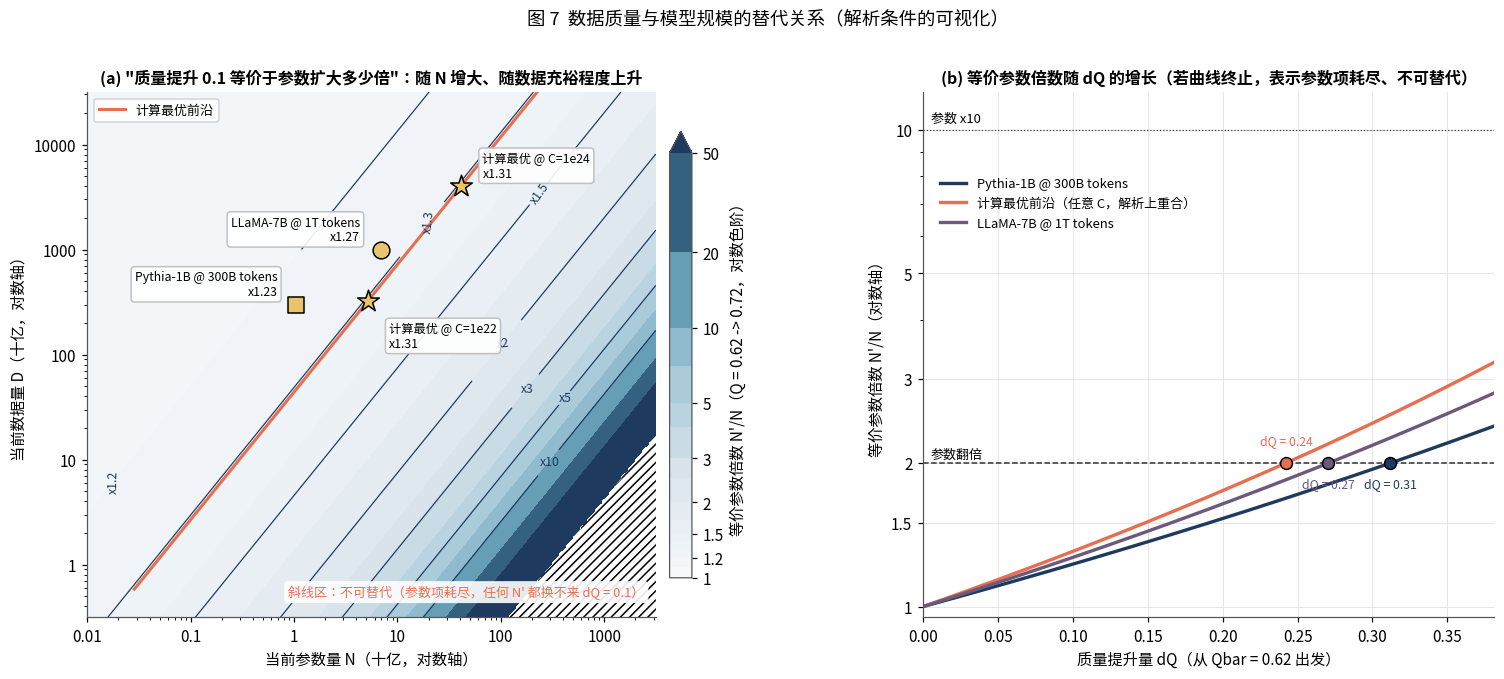

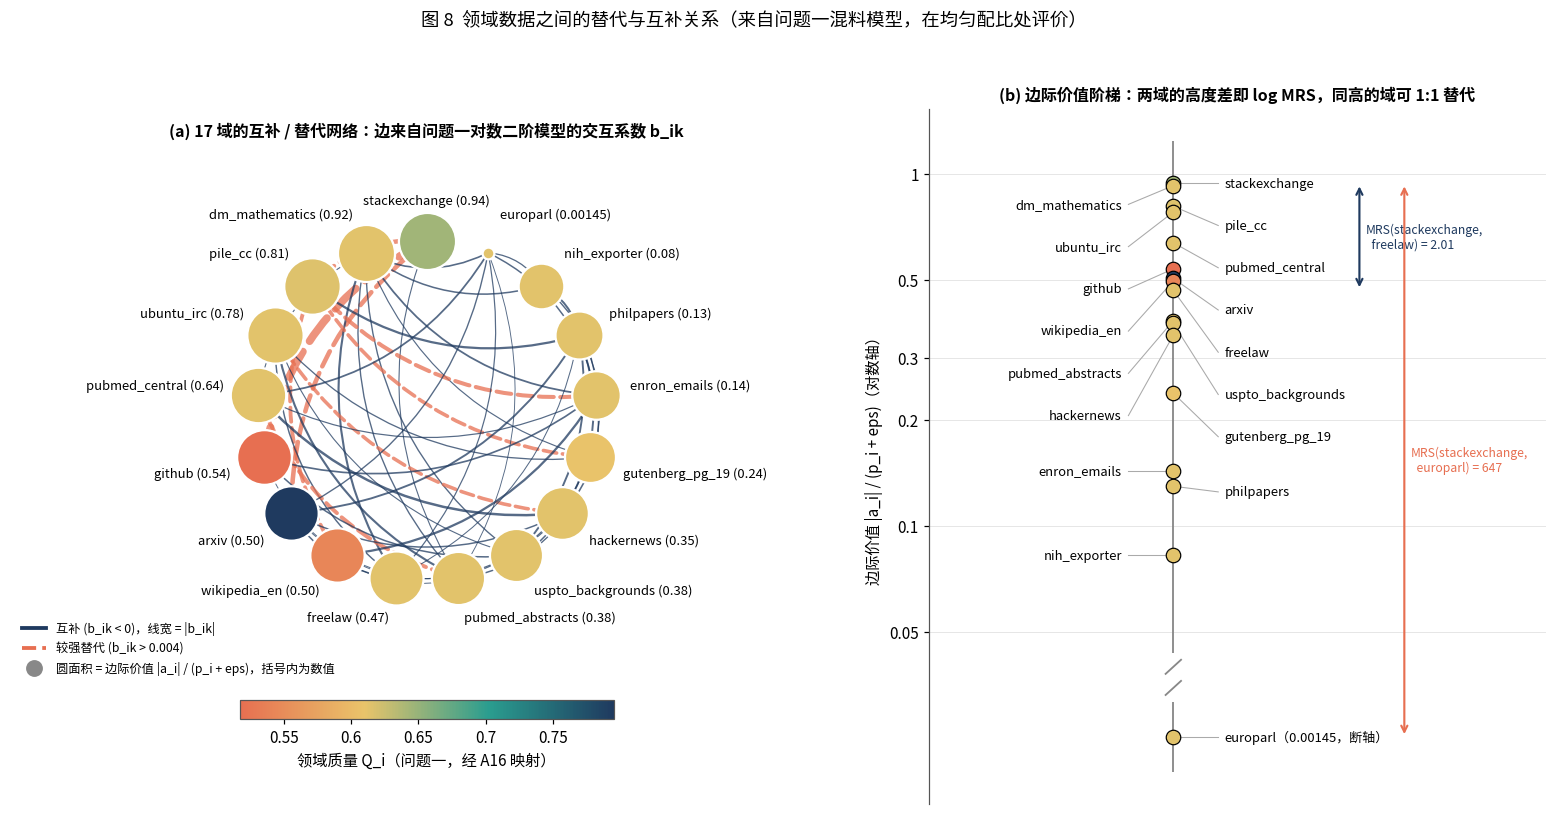

In [8]:
# ============ 5. 广义标度律：函数、弹性表、单位算力回报、替代条件、领域 MRS ============
def L_general(N, D, Q=1.0, p=None, kappa=None):
    psi = psi_Q(Q, kappa) * (1.0 if p is None else psi_p(p))
    return TH['E'] + R_fun(N, D) * psi
def elasticities(N, D, Q=1.0, p=None):
    N = float(N); D = float(D); Q = float(Q); pp = 1.0 if p is None else float(psi_p(p)); Psi = psi_Q(Q) * pp
    L = L_general(N, D, Q, p); R = R_fun(N, D)
    return {'L': L, 'MU_N': TH['alpha'] * TH['A'] * N ** (-TH['alpha'] - 1) * Psi, 'MU_D': TH['beta'] * TH['B'] * D ** (-TH['beta'] - 1) * Psi, 'MU_Q': KAPPA * R * pp,
            'eps_N': -TH['alpha'] * TH['A'] * N ** (-TH['alpha']) * Psi / L, 'eps_D': -TH['beta'] * TH['B'] * D ** (-TH['beta']) * Psi / L, 'eps_Q': -KAPPA * Q * R * pp / L}
# 附录 B 的三类质量成本函数 g(Q) 及其导数
G_COST = {'指数型 g = 1e7 exp(6Q)': (lambda Q: 1e7 * np.exp(6.0 * Q), lambda Q: 1e7 * 6.0 * np.exp(6.0 * Q)),
          '幂函数型 g = 5e9 Q^4': (lambda Q: 5e9 * Q ** 4.0, lambda Q: 5e9 * 4.0 * Q ** 3.0),
          '对数渐进型 g = 2e9 ln(1+10Q)': (lambda Q: 2e9 * np.log(1 + 10.0 * Q), lambda Q: 2e9 * 10.0 / (1 + 10.0 * Q))}
Q_BAR = float(Q1['Qbar_p_star'])
REF = [('Pythia-1B @ 300B tokens', 1.04e9, 3e11), ('计算最优 @ C=1e22', float(N_opt(1e22)), float(D_opt(1e22))), ('LLaMA-7B @ 1T tokens', 7e9, 1e12), ('计算最优 @ C=1e24', float(N_opt(1e24)), float(D_opt(1e24)))]
rows = []
for name, N_, D_ in REF:
    for Q_ in (1.0, 0.8, Q_BAR):
        e = elasticities(N_, D_, Q_); r = {'参考点': name, 'N(B)': N_ / 1e9, 'D(B)': D_ / 1e9, 'Q': Q_, 'L': e['L'], 'eps_N': e['eps_N'], 'eps_D': e['eps_D'], 'eps_Q': e['eps_Q'],
                                            'log10 每FLOP下降(N)': np.log10(e['MU_N'] / (6 * D_)), 'log10 每FLOP下降(D)': np.log10(e['MU_D'] / (6 * N_))}
        for gname, (g, gp) in G_COST.items(): r['log10 每FLOP下降(Q,' + gname.split(' ')[0] + ')'] = np.log10(e['MU_Q'] / (D_ * gp(Q_)))
        rows.append(r)
ELAS = pd.DataFrame(rows); print('参考点处的弹性与单位算力回报（Q = %.3f 为问题一 p* 的配比级质量；每 FLOP 的损失下降取 log10）:' % Q_BAR); display(ELAS)
ELAS.to_csv(TAB / 'elasticities_reference_points.csv', index=False, encoding='utf-8-sig')

# 质量-规模替代：等价参数倍数与存在条件
def N_equiv(N, D, Q, dQ=0.1):
    R = R_fun(N, D); target = R * psi_Q(np.minimum(Q + dQ, 1.0)) / psi_Q(Q) - TH['B'] * np.asarray(D, float) ** (-TH['beta'])
    with np.errstate(invalid='ignore', divide='ignore'):
        Np = np.where(target > 0, (target / TH['A']) ** (-1 / TH['alpha']), np.nan)
    return Np
def dQ_equiv_double(N, D, Q):
    return (psi_Q(Q) - psi_Q(Q) * R_fun(2 * np.asarray(N, float), D) / R_fun(N, D)) / KAPPA
rows = []
for name, N_, D_ in REF:
    for Q_ in (0.5, 0.7, 0.9):
        Np = float(N_equiv(N_, D_, Q_)); rows.append({'参考点': name, 'Q': Q_, '等价参数倍数 N\'/N (dQ=0.1)': Np / N_ if np.isfinite(Np) else np.inf, '参数翻倍等价的 dQ': float(dQ_equiv_double(N_, D_, Q_)), '条件 R psi(Q+0.1)/psi(Q) > B D^-beta': bool(np.isfinite(Np))})
SUB = pd.DataFrame(rows); print('\n质量-规模替代（D 不变）:'); display(SUB); SUB.to_csv(TAB / 'quality_scale_substitution.csv', index=False, encoding='utf-8-sig')
rr_ = psi_Q(Q_BAR + 0.1) / psi_Q(Q_BAR); M_front = (rr_ + (TH['alpha'] / TH['beta']) * (rr_ - 1)) ** (-1 / TH['alpha'])
print('解析：N\'/N 只依赖比值 B D^-beta / (A N^-alpha)，在计算最优前沿上该比值恒为 alpha/beta，故 dQ = 0.1 的等价参数倍数沿前沿为常数 = %.3f（与 C 无关）；替代存在条件在前沿上恒成立（beta/alpha (psi\'/psi - 1) + psi\'/psi = %.3f > 0）' % (M_front, rr_ + (TH['alpha'] / TH['beta']) * (rr_ - 1)))

# 领域 MRS（均匀配比处）与互补/替代标记（问题一交互项）
INT = pd.read_csv(BASE_DIR / 'output_q1' / 'tables' / 'domain_interactions.csv')
Bint = pd.DataFrame(0.0, index=DOM17, columns=DOM17)
for _, r in INT.iterrows(): Bint.loc[r['域i'], r['域k']] = r['b_ik']; Bint.loc[r['域k'], r['域i']] = r['b_ik']
mv = A_LOG / (uniform + EPS_LOG); MRS = pd.DataFrame(np.outer(mv, 1 / mv), index=DOM17, columns=DOM17)
print('\n均匀配比处的边际价值 a_i/(p_i+eps)（越负越值钱）:'); print(pd.Series(mv, index=DOM17).sort_values().round(3).to_string())
MRS.to_csv(TAB / 'domain_MRS_uniform.csv', encoding='utf-8-sig')

# 解析结果：沿计算最优前沿 alpha A N^-alpha = beta B D^-beta，故 |eps_N| = |eps_D|，且三者的份额与 C 无关、只随 Q 变化
sh_ND = 2 * TH['alpha'] * TH['beta'] / (TH['alpha'] + TH['beta'])
print('\n沿前沿的弹性份额（解析）: |eps_N| : |eps_D| : |eps_Q| = %.3f : %.3f : kappa Q / psi_Q(Q)  -> 与 C 无关；Q = %.2f 时质量份额 = %.3f, Q = 1 时 = %.3f' % (sh_ND / 2, sh_ND / 2, Q_BAR, (KAPPA * Q_BAR / psi_Q(Q_BAR)) / (KAPPA * Q_BAR / psi_Q(Q_BAR) + sh_ND), KAPPA / (KAPPA + sh_ND)))
# 每 FLOP 回报比（买好教材 / 堆参数）= 6 kappa R / (g'(Q) alpha A N^(-alpha-1) psi_Q)，D 与 psi_p 均约掉；>1 表示同样的算力用于提升质量更划算
def return_ratio(N, D, Q, gp):
    N = np.asarray(N, float); D = np.asarray(D, float); Q = np.asarray(Q, float)
    return 6 * KAPPA * R_fun(N, D) / (gp(Q) * TH['alpha'] * TH['A'] * N ** (-TH['alpha'] - 1) * psi_Q(Q))
for gname, (g, gp) in G_COST.items():
    print('  %s: 前沿上 C=1e19/1e22/1e24 处、Q=%.2f 的回报比 = %.2f / %.2f / %.2f' % (gname, Q_BAR, *[float(return_ratio(N_opt(C), D_opt(C), Q_BAR, gp)) for C in (1e19, 1e22, 1e24)]))

# ---- 图 6：(a) 弹性份额随 Q 的剖面（前沿上与 C 无关） + (b) 决策地图：每 FLOP 回报比 ----
fig = plt.figure(figsize=(16.5, 6)); gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.15], wspace=0.22)
ax = fig.add_subplot(gs[0]); Qg = np.linspace(0.3, 1.0, 200); N0_, D0_ = float(N_opt(1e22)), float(D_opt(1e22))
E_ = np.array([[abs(elasticities(N0_, D0_, q)[k]) for k in ('eps_N', 'eps_D', 'eps_Q')] for q in Qg]); shr = E_ / E_.sum(axis=1, keepdims=True)
ax.stackplot(Qg, shr[:, 0], shr[:, 1], shr[:, 2], colors=[C_NAVY, C_TEAL, C_GOLD], alpha=0.92, labels=['|eps_N| 参数弹性份额', '|eps_D| 数据弹性份额', '|eps_Q| 质量弹性份额'])
# 前沿之外（数据远多于前沿比例的 Pythia-1B @ 300B）：参数弹性份额上升，用白色虚线画出其两条分界
E1 = np.array([[abs(elasticities(1.04e9, 3e11, q)[k]) for k in ('eps_N', 'eps_D', 'eps_Q')] for q in Qg]); sh1 = E1 / E1.sum(axis=1, keepdims=True)
ax.plot(Qg, sh1[:, 0], color='white', lw=1.6, ls='--'); ax.plot(Qg, sh1[:, 0] + sh1[:, 1], color='white', lw=1.6, ls='--', label='前沿之外 (Pythia-1B @ 300B, D/N = 288) 的分界')
for q_, lab_ in ((Q_BAR, 'Qbar = %.2f' % Q_BAR), (0.8, 'Q = 0.8')):
    ax.axvline(q_, color='white', lw=0.9, ls=':'); ax.text(q_ + 0.008, 0.02, lab_, fontsize=8.5, color='white')
ax.text(0.5, 0.5 * shr[len(Qg) // 2, 0], '沿前沿 |eps_N| = |eps_D|，\n份额与 C 无关（解析）', color='white', fontsize=9, ha='center', va='center')
ax.set_xlim(0.3, 1.0); ax.set_ylim(0, 1); ax.set_xlabel('数据质量 Q'); ax.set_ylabel('弹性绝对值的份额'); ax.legend(loc='upper left', frameon=True, fontsize=8.5, facecolor='#CFCFCF', framealpha=0.95)
ax.set_title('(a) 三种因素的弹性份额随 Q 的剖面：质量越接近 1，质量弹性份额越大', fontsize=10.5)
ax = fig.add_subplot(gs[1])
Cs = np.logspace(17, 26, 220); Qg2 = np.linspace(0.3, 1.0, 160); CC, QQ = np.meshgrid(Cs, Qg2); Nf, Df = N_opt(CC), D_opt(CC)
gp_exp = G_COST['指数型 g = 1e7 exp(6Q)'][1]; RR = np.log10(return_ratio(Nf, Df, QQ, gp_exp))
vm = np.ceil(np.nanmax(np.abs(RR))); cf = ax.contourf(CC, QQ, RR, levels=np.linspace(-vm, vm, 41), cmap=CMAP_DIV)
for (gname, (g, gp)), c, ls in zip(G_COST.items(), [C_NAVY, C_CORAL, C_PLUM], ['-', '--', '-.']):
    cs = ax.contour(CC, QQ, np.log10(return_ratio(Nf, Df, QQ, gp)), levels=[0], colors=[c], linewidths=2.2, linestyles=ls); ax.plot([], [], color=c, ls=ls, lw=2.2, label='盈亏平衡线（回报比 = 1）：%s' % gname.split(' ')[0])
for C in (1e19, 1e22, 1e24): ax.axvline(C, color='#333333', lw=0.9, ls=':')
ax.axhline(Q_BAR, color='#333333', lw=0.9, ls=':'); ax.text(1.3e17, Q_BAR + 0.01, 'Qbar = %.2f' % Q_BAR, fontsize=8.5)
ax.text(0.02, 0.96, '右上（暖色）：买好教材更划算\n左下（冷色）：堆参数更划算', transform=ax.transAxes, va='top', fontsize=9, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC', alpha=0.9))
ax.set_xscale('log'); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: '1e%d' % int(round(np.log10(v))))); ax.grid(False)
ax.set_xlabel('算力预算 C (FLOPs)，(N, D) 取计算最优前沿'); ax.set_ylabel('当前数据质量 Q'); ax.legend(loc='lower right', frameon=True, fontsize=8.5, facecolor='white', framealpha=0.9)
cb = plt.colorbar(cf, ax=ax, shrink=0.85, pad=0.02, ticks=np.arange(-vm, vm + 0.5, 1), format=plain); cb.set_label('log10 回报比 rho（底色按指数型成本）：> 0 买好教材更划算')
ax.set_title('(b) 决策地图："同样多花一块钱"用在买好教材还是堆参数（附录 B 三类成本函数）', fontsize=10.5)
fig.suptitle('图 6  广义标度律下的边际效用与弹性', fontsize=12, y=1.0)
savefig('fig06_elasticity_shares.png'); plt.show()

# ---- 图 7：质量-规模替代地图 ----
fig = plt.figure(figsize=(16.5, 6.2)); gs = gridspec.GridSpec(1, 2, width_ratios=[1.2, 1], wspace=0.24)
# (a) 在 (N, D) 平面上、Q = Qbar 时，质量提升 0.1 的等价参数倍数；右下角（参数多、数据少）参数项耗尽 -> 不可替代
Ng7 = np.logspace(7, 12.5, 240); Dg7 = np.logspace(8.5, 13.5, 240); NN7, DD7 = np.meshgrid(Ng7, Dg7)
M7 = N_equiv(NN7, DD7, Q_BAR) / NN7; ax = fig.add_subplot(gs[0])
lv = [1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.7, 2, 2.5, 3, 4, 5, 7, 10, 20, 50]; cf = ax.contourf(NN7 / 1e9, DD7 / 1e9, M7, levels=lv, cmap=CMAP_TERRAIN, norm=mpl.colors.LogNorm(vmin=1, vmax=50), extend='max')
cs = ax.contour(NN7 / 1e9, DD7 / 1e9, M7, levels=[1.2, 1.3, 1.5, 2, 3, 5, 10], colors='#1F3A5F', linewidths=0.8); ax.clabel(cs, fmt=lambda v: 'x%g' % v, fontsize=8)
infeas = np.isnan(M7)
if infeas.any(): ax.contourf(NN7 / 1e9, DD7 / 1e9, infeas.astype(float), levels=[0.5, 1.5], colors='none', hatches=['////']); ax.text(0.98, 0.04, '斜线区：不可替代（参数项耗尽，任何 N\' 都换不来 dQ = 0.1）', transform=ax.transAxes, ha='right', fontsize=8.5, color=C_CORAL, bbox=dict(boxstyle='round', fc='white', ec='none', alpha=0.9))
ax.set_xlim(Ng7.min() / 1e9, Ng7.max() / 1e9); ax.set_ylim(Dg7.min() / 1e9, Dg7.max() / 1e9)
Cs7 = np.logspace(17, 27, 100); ax.plot(N_opt(Cs7) / 1e9, D_opt(Cs7) / 1e9, color=C_CORAL, lw=2, label='计算最优前沿')
for (name, N_, D_), mk, off, ha_ in zip(REF, ['s', '*', 'o', '*'], [(-12, 6), (14, -30), (-14, 6), (14, 6)], ['right', 'left', 'right', 'left']):
    ax.scatter([N_ / 1e9], [D_ / 1e9], marker=mk, s=120 if mk != '*' else 220, color=C_GOLD, edgecolor='black', zorder=6); ax.annotate('%s\nx%.2f' % (name, float(N_equiv(N_, D_, Q_BAR)) / N_), (N_ / 1e9, D_ / 1e9), xytext=off, textcoords='offset points', fontsize=8, ha=ha_, bbox=dict(boxstyle='round', fc='white', ec='#BBBBBB', alpha=0.9), zorder=7)
ax.set_xscale('log'); ax.set_yscale('log'); ax.xaxis.set_major_formatter(plain); ax.yaxis.set_major_formatter(plain); ax.grid(False)
ax.set_xlabel('当前参数量 N（十亿，对数轴）'); ax.set_ylabel('当前数据量 D（十亿，对数轴）'); ax.legend(loc='upper left', frameon=True, fontsize=8.5)
cb = plt.colorbar(cf, ax=ax, shrink=0.85, pad=0.02, ticks=[1, 1.2, 1.5, 2, 3, 5, 10, 20, 50], format=plain); cb.set_label('等价参数倍数 N\'/N（Q = %.2f -> %.2f，对数色阶）' % (Q_BAR, Q_BAR + 0.1))
ax.set_title('(a) "质量提升 0.1 等价于参数扩大多少倍"：随 N 增大、随数据充裕程度上升', fontsize=10.5)
# (b) 等价参数倍数随质量提升量 dQ 的曲线（从 Qbar 出发），曲线终止处为替代极限；水平线 = 参数翻倍
ax = fig.add_subplot(gs[1]); dQs = np.linspace(0, 1 - Q_BAR, 300)
# 前沿上 B D^-beta / (A N^-alpha) = alpha / beta 为常数，故 N'/N 沿前沿与 C 无关（1e22 与 1e24 两点重合），只画一条
REF_B = [(REF[0][0], REF[0][1], REF[0][2]), ('计算最优前沿（任意 C，解析上重合）', REF[1][1], REF[1][2]), (REF[2][0], REF[2][1], REF[2][2])]
for (name, N_, D_), c, dy in zip(REF_B, [C_NAVY, C_CORAL, C_PLUM], [-16, 12, -16]):
    Mv = N_equiv(N_, D_, Q_BAR, dQs) / N_; ok = np.isfinite(Mv); ax.plot(dQs[ok], Mv[ok], color=c, lw=2.2, label=name)
    if np.nanmax(Mv[ok]) >= 2:                                          # 与"参数翻倍"等价的 dQ
        dq2 = float(np.interp(2.0, Mv[ok], dQs[ok])); ax.scatter([dq2], [2.0], s=60, color=c, edgecolor='black', zorder=6); ax.annotate('dQ = %.2f' % dq2, (dq2, 2.0), xytext=(0, dy), textcoords='offset points', ha='center', fontsize=8, color=c)
    if (~ok).any():
        lim_ = dQs[ok].max(); ax.scatter([lim_], [Mv[ok][-1]], marker='x', s=70, color=c, linewidths=2, zorder=6); ax.text(lim_, Mv[ok][-1] * 1.12, '替代极限 dQ = %.2f' % lim_, color=c, fontsize=8, ha='right')
ax.axhline(2, color='#333333', lw=1, ls='--'); ax.text(0.005, 2.05, '参数翻倍', fontsize=8.5)
ax.axhline(10, color='#333333', lw=0.8, ls=':'); ax.text(0.005, 10.4, '参数 x10', fontsize=8.5)
ax.set_yscale('log'); ax.set_yticks([1, 1.5, 2, 3, 5, 10]); ax.yaxis.set_major_formatter(plain); ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter()); ax.set_xlim(0, 1 - Q_BAR); ax.set_ylim(0.95, 12); ax.set_xlabel('质量提升量 dQ（从 Qbar = %.2f 出发）' % Q_BAR); ax.set_ylabel('等价参数倍数 N\'/N（对数轴）')
ax.legend(frameon=False, fontsize=8.5, loc='upper left', bbox_to_anchor=(0.01, 0.86)); ax.set_title('(b) 等价参数倍数随 dQ 的增长（若曲线终止，表示参数项耗尽、不可替代）', fontsize=10.5)
fig.suptitle('图 7  数据质量与模型规模的替代关系（解析条件的可视化）', fontsize=12, y=1.0)
savefig('fig07_quality_scale_substitution.png'); plt.show()

# ---- 图 8：领域数据的替代 / 互补网络（环形）+ 边际价值阶梯（MRS 直接读作两域高度差） ----
order = list(pd.Series(mv, index=DOM17).sort_values().index)          # 边际价值从高到低（mv 越负越值钱）
val = pd.Series(-mv, index=DOM17)                                        # 正的边际价值 |a_i| / (p_i + eps)
normQ = mpl.colors.Normalize(vmin=Q17.min(), vmax=Q17.max()); CMAP_Q = mpl.colors.LinearSegmentedColormap.from_list('q', ['#E76F51', '#E9C46A', '#2A9D8F', '#1F3A5F'])
fig = plt.figure(figsize=(18, 8.2)); gs = gridspec.GridSpec(1, 2, width_ratios=[1.35, 1], wspace=0.12)
ax = fig.add_subplot(gs[0]); ax.set_aspect('equal'); ax.axis('off')
n_ = len(order); th_ = np.pi / 2 + np.linspace(0, 2 * np.pi, n_, endpoint=False); pos = {d: (np.cos(t), np.sin(t)) for d, t in zip(order, th_)}
bmax = np.abs(Bint.values).max()
from matplotlib.patches import FancyArrowPatch
for a_i in range(n_):
    for b_i in range(a_i + 1, n_):
        di, dk = order[a_i], order[b_i]; b = Bint.loc[di, dk]
        if b < 0: col, ls, lw = C_NAVY, '-', 0.6 + 4.5 * abs(b) / bmax
        elif b > 0.004: col, ls, lw = C_CORAL, '--', 0.6 + 4.5 * abs(b) / bmax
        else: continue
        ax.add_patch(FancyArrowPatch(pos[di], pos[dk], connectionstyle='arc3,rad=0.25', arrowstyle='-', color=col, lw=lw, ls=ls, alpha=0.75, zorder=1))
smin, smax = 60, 1400; vlog = np.log10(val.clip(lower=1e-3)); sz = smin + (smax - smin) * (vlog - vlog.min()) / (vlog.max() - vlog.min())
for d in order:
    x_, y_ = pos[d]; ax.scatter([x_], [y_], s=sz[d], color=CMAP_Q(normQ(Q17[d])), edgecolor='white', linewidths=1.5, zorder=3)
    ha_ = 'left' if x_ > 0.05 else ('right' if x_ < -0.05 else 'center'); va_ = 'bottom' if y_ > 0.05 else ('top' if y_ < -0.05 else 'center')
    ax.text(x_ * 1.2, y_ * 1.2, '%s (%s)' % (d, ('%.2f' % val[d]) if val[d] >= 0.01 else ('%.3g' % val[d])), ha=ha_, va=va_, fontsize=8.5)
ax.set_xlim(-2.45, 2.45); ax.set_ylim(-1.62, 1.55)
ax.legend(handles=[Line2D([0], [0], color=C_NAVY, lw=2.5, label='互补 (b_ik < 0)，线宽 = |b_ik|'), Line2D([0], [0], color=C_CORAL, lw=2.5, ls='--', label='较强替代 (b_ik > 0.004)'),
                   Line2D([0], [0], marker='o', ls='', color='#888888', ms=10, label='圆面积 = 边际价值 |a_i| / (p_i + eps)，括号内为数值')],
          loc='lower left', bbox_to_anchor=(0.0, 0.0), frameon=False, fontsize=8)
sm = mpl.cm.ScalarMappable(norm=normQ, cmap=CMAP_Q); cb = plt.colorbar(sm, ax=ax, shrink=0.45, pad=0.02, orientation='horizontal', format=plain); cb.set_label('领域质量 Q_i（问题一，经 A16 映射）')
ax.set_title('(a) 17 域的互补 / 替代网络：边来自问题一对数二阶模型的交互系数 b_ik', fontsize=10.5, pad=8)
# (b) 边际价值阶梯：对数轴上两域的高度差 = log MRS；标签做最小间距排斥
ax = fig.add_subplot(gs[1]); vv = val[order].values; lv_true = np.log10(vv)
# 价值极小的域（如 a_i 约为 0 的域）会把阶梯压扁：把低于 0.05 的域放到断轴之下
ycut = np.log10(0.05); trunc = lv_true < ycut; lv_ = lv_true.copy(); lv_[trunc] = ycut - 0.3 - 0.08 * np.arange(trunc.sum())
ylab = lv_.copy(); gap = 0.06
for k in range(1, n_):
    if ylab[k - 1] - ylab[k] < gap: ylab[k] = ylab[k - 1] - gap          # order 按价值从高到低
ax.vlines(0, ycut - 0.06, lv_.max() + 0.12, color='#888888', lw=1.2); ax.vlines(0, lv_.min() - 0.1, ycut - 0.2, color='#888888', lw=1.2)
for dy_ in (ycut - 0.10, ycut - 0.16): ax.plot([-0.06, 0.06], [dy_ - 0.02, dy_ + 0.02], color='#888888', lw=1.2)
for k, d in enumerate(order):
    side = 1 if k % 2 == 0 else -1
    ax.scatter([0], [lv_[k]], s=90, color=CMAP_Q(normQ(Q17[d])), edgecolor='black', linewidths=0.8, zorder=4)
    lab_ = d if not trunc[k] else '%s（%.3g，断轴）' % (d, vv[k])
    ax.plot([0, side * 0.35], [lv_[k], ylab[k]], color='#AAAAAA', lw=0.7); ax.text(side * 0.4, ylab[k], lab_, ha='left' if side > 0 else 'right', va='center', fontsize=8.5)
# 示例替代率：最高价值域 vs 中位域、vs 末位域
top, midd, last = order[0], order[n_ // 2], order[-1]
for dk, xo, col in ((midd, 1.45, C_NAVY), (last, 1.8, C_CORAL)):
    ax.annotate('', xy=(xo, lv_[order.index(dk)]), xytext=(xo, lv_[0]), arrowprops=dict(arrowstyle='<->', color=col, lw=1.4))
    ax.text(xo + 0.05, 0.5 * (lv_[0] + lv_[order.index(dk)]), 'MRS(%s,\n  %s) = %.3g' % (top, dk, MRS.loc[top, dk]), fontsize=8, color=col, va='center')
tk_ = [t for t in (0.05, 0.1, 0.2, 0.3, 0.5, 1) if np.log10(t) >= ycut - 0.01 and np.log10(t) <= lv_.max() + 0.2]
ax.set_xlim(-1.9, 2.9); ax.set_yticks(np.log10(tk_)); ax.set_yticklabels(['%g' % t for t in tk_]); ax.set_xticks([])
for sp in ('top', 'right', 'bottom'): ax.spines[sp].set_visible(False)
ax.set_ylabel('边际价值 |a_i| / (p_i + eps)（对数轴）'); ax.set_title('(b) 边际价值阶梯：两域的高度差即 log MRS，同高的域可 1:1 替代', fontsize=10.5)
fig.suptitle('图 8  领域数据之间的替代与互补关系（来自问题一混料模型，在均匀配比处评价）', fontsize=12, y=0.99)
savefig('fig08_domain_MRS.png'); plt.show()

## 6. 百亿参数以上的外推与不确定性

**B10 的性质**。B10 给出的 100B–10000B 模型"预估 Loss"是《数据说明》标注的 **估算值**：用同一定律的 $(N,D)$ 代入即可复现（下面验证），因此它不是外推的独立证据，只能用来检查 B9 中真实模型的 $(N,D)$ 处在前沿的哪一侧。

**指数的不确定性**。B1 残差为零，无法给出置信区间；本文用真实跨族数据（B4 + B5，20 个来源，101 点）在 H1 的结构 $L=E_f+s_fR_{\alpha,\beta}(N,D)$ 下 **重新识别** $\alpha,\beta$：外层对 $(\alpha,\beta)$ 做数值优化，内层对每个来源用线性最小二乘解 $(E_f,s_f)$（不足 3 点的来源只估偏移）。再做 **来源级 Bootstrap**（有放回重抽 20 个来源，200 次），得到 $\alpha,\beta$ 的经验分布；把这些指数代入前沿并按 B1 重新校准 $(E,A,B)$，得到 100B 以上损失预测的扇形带。$\kappa$ 的 Bootstrap 区间给出质量项的带宽。

B10 估算 Loss 与本文经典定律的预测: RMSE = 0.0011, 最大绝对差 = 0.0052, Spearman = 1.000  -> B10 由同一定律估算得到，非独立证据
B9 真实大模型 (128 个有 N,D 的模型): token/参数比中位数 6，同算力下计算最优比中位数 108；相对前沿的损失冗余中位数 0.0201
  其中开源权重模型 66 个，token/参数比中位数 16（闭源/未发布 3）

真实跨族数据重新识别的指数: alpha = 0.284, beta = 0.254（B1: 0.340, 0.280）; 来源级 Bootstrap 200 次 95% CI: alpha [0.183, 0.291], beta [0.167, 0.294]  耗时 67s


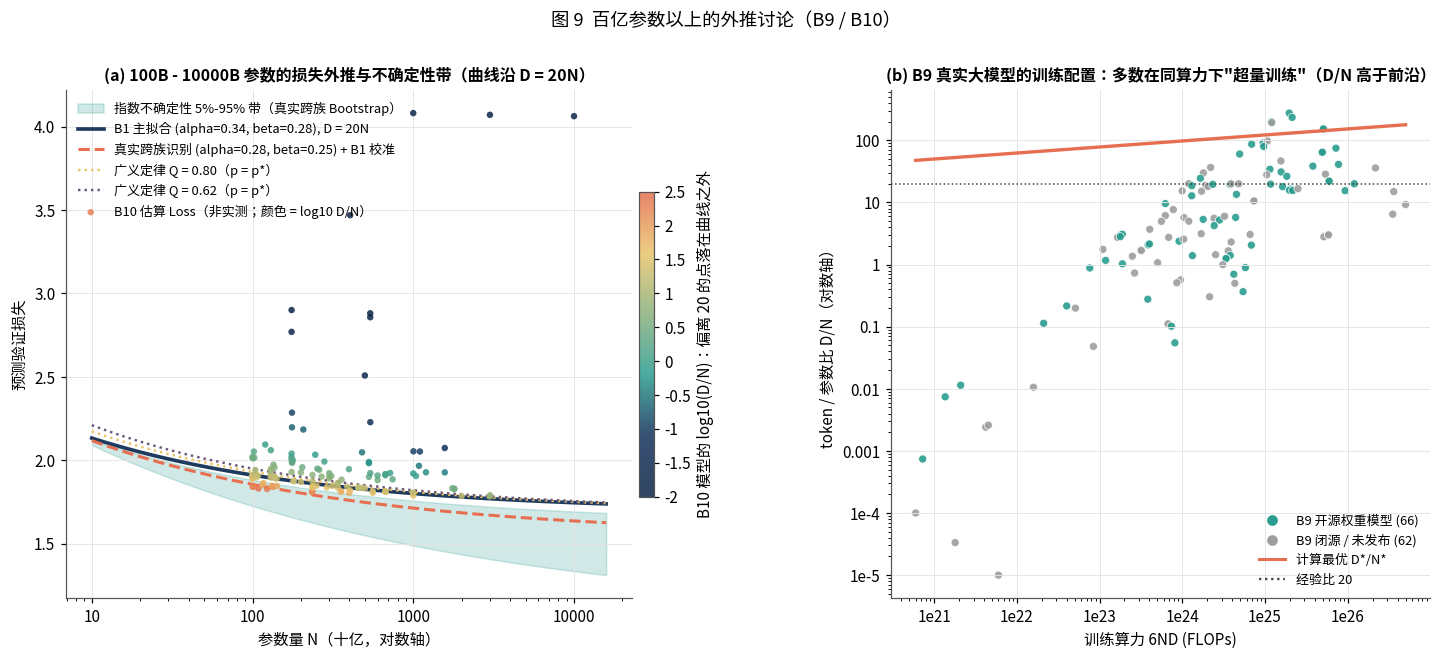

In [9]:
# ============ 6. 外推与不确定性 ============
B10['pred'] = L_classic(B10.N, B10.D, TH)
print('B10 估算 Loss 与本文经典定律的预测: RMSE = %.4f, 最大绝对差 = %.4f, Spearman = %.3f  -> B10 由同一定律估算得到，非独立证据' % (rmse(B10.val_loss, B10.pred), (B10.val_loss - B10.pred).abs().max(), stats.spearmanr(B10.val_loss, B10.pred)[0]))
B9c = B9.dropna(subset=['N_params_B', 'D_tokens_B']); B9c = B9c[(B9c.D_tokens_B > 0)].copy(); B9c['N'] = B9c.N_params_B * 1e9; B9c['D'] = B9c.D_tokens_B * 1e9
B9c['C_6ND'] = 6 * B9c.N * B9c.D; B9c['D_over_N'] = B9c.D / B9c.N; B9c['Dopt_over_N'] = D_opt(B9c.C_6ND) / N_opt(B9c.C_6ND)
B9c['pred_L'] = L_classic(B9c.N, B9c.D, TH); B9c['L_at_frontier'] = L_classic(N_opt(B9c.C_6ND), D_opt(B9c.C_6ND), TH)
print('B9 真实大模型 (%d 个有 N,D 的模型): token/参数比中位数 %.0f，同算力下计算最优比中位数 %.0f；相对前沿的损失冗余中位数 %.4f' % (len(B9c), B9c.D_over_N.median(), B9c.Dopt_over_N.median(), (B9c.pred_L - B9c.L_at_frontier).median()))
opw = B9c.accessibility.fillna('').str.contains('Open weights'); print('  其中开源权重模型 %d 个，token/参数比中位数 %.0f（闭源/未发布 %.0f）' % (opw.sum(), B9c.loc[opw, 'D_over_N'].median(), B9c.loc[~opw, 'D_over_N'].median()))

# 跨族数据重新识别指数（H1 结构）+ 来源级 Bootstrap
CF = pd.concat([B4.assign(grp='B4:' + B4.family)[['grp', 'N', 'D', 'val_loss']], B5.assign(grp='B5:' + B5.family)[['grp', 'N', 'D', 'val_loss']]], ignore_index=True)
def sse_exp(th, df):
    al, be = th; R = TH['A'] * df.N.values ** (-al) + TH['B'] * df.D.values ** (-be); L = df.val_loss.values; g = df.grp.values; pred = np.zeros_like(L)
    for k in np.unique(g):
        m = g == k
        if m.sum() >= 3:
            X = np.column_stack([np.ones(m.sum()), R[m]]); c, _, _, _ = np.linalg.lstsq(X, L[m], rcond=None); pred[m] = X @ c
        else: pred[m] = (L[m] - R[m]).mean() + R[m]
    return ((L - pred) ** 2).sum()
def fit_exp(df, starts=None):
    best = None
    for a0, b0 in (starts or list(itertools.product([0.2, 0.35, 0.5], [0.2, 0.35, 0.5]))):
        r = minimize(lambda th: sse_exp(th, df), [a0, b0], bounds=[(0.05, 1.2), (0.05, 1.2)], method='L-BFGS-B')
        if best is None or r.fun < best.fun: best = r
    return best.x
t0 = time.time(); AB_real = fit_exp(CF); groups = CF.grp.unique(); boot = []
for b in range(200):
    pick = RNG.choice(groups, len(groups), replace=True); dfb = pd.concat([CF[CF.grp == k].assign(grp=k + '#%d' % i) for i, k in enumerate(pick)], ignore_index=True); boot.append(fit_exp(dfb, starts=[tuple(AB_real), (0.2, 0.2), (0.5, 0.5)]))
boot = np.array(boot); print('\n真实跨族数据重新识别的指数: alpha = %.3f, beta = %.3f（B1: %.3f, %.3f）; 来源级 Bootstrap 200 次 95%% CI: alpha [%.3f, %.3f], beta [%.3f, %.3f]  耗时 %.0fs' % (AB_real[0], AB_real[1], TH['alpha'], TH['beta'], *np.percentile(boot[:, 0], [2.5, 97.5]), *np.percentile(boot[:, 1], [2.5, 97.5]), time.time() - t0))
EXP_UNC = {'alpha_real': float(AB_real[0]), 'beta_real': float(AB_real[1]), 'alpha_ci': np.percentile(boot[:, 0], [2.5, 97.5]).tolist(), 'beta_ci': np.percentile(boot[:, 1], [2.5, 97.5]).tolist(), 'boot': boot.tolist()}
json.dump(EXP_UNC, open(TAB / 'exponent_uncertainty.json', 'w', encoding='utf-8'), ensure_ascii=False)

# 给定 (alpha, beta)，按 B1 重新校准 (E, A, B)（线性最小二乘），用于扇形带
def recalib(al, be):
    X = np.column_stack([np.ones(len(B1)), B1.N ** (-al), B1.D ** (-be)]); c, _, _, _ = np.linalg.lstsq(X, B1.val_loss.values, rcond=None)
    return {'E': c[0], 'A': c[1], 'alpha': al, 'B': c[2], 'beta': be}
Nx = np.logspace(10, 13.2, 120); Cx = 6 * Nx * 20 * Nx                      # 沿 D = 20N 的路径外推
fan = np.array([L_classic(Nx, 20 * Nx, recalib(a, b)) for a, b in boot[:120]])
lo_, hi_ = np.percentile(fan, [5, 95], axis=0); base_ = L_classic(Nx, 20 * Nx, TH); real_ = L_classic(Nx, 20 * Nx, recalib(*AB_real))

# ---- 图 9：百亿以上外推扇形带 + B9/B10 ----
fig = plt.figure(figsize=(16, 6)); gs = gridspec.GridSpec(1, 2, width_ratios=[1.25, 1], wspace=0.25)
ax = fig.add_subplot(gs[0])
ax.fill_between(Nx / 1e9, lo_, hi_, color=C_TEAL, alpha=0.22, label='指数不确定性 5%-95% 带（真实跨族 Bootstrap）')
ax.plot(Nx / 1e9, base_, color=C_NAVY, lw=2.4, label='B1 主拟合 (alpha=%.2f, beta=%.2f), D = 20N' % (TH['alpha'], TH['beta']))
ax.plot(Nx / 1e9, real_, color=C_CORAL, lw=2, ls='--', label='真实跨族识别 (alpha=%.2f, beta=%.2f) + B1 校准' % (AB_real[0], AB_real[1]))
for Q_, c in ((0.8, C_GOLD), (Q_BAR, C_PLUM)):
    ax.plot(Nx / 1e9, TH['E'] + R_fun(Nx, 20 * Nx) * psi_Q(Q_), color=c, lw=1.6, ls=':', label='广义定律 Q = %.2f（p = p*）' % Q_)
ratio10 = np.log10(B10.D_tokens_B / B10.N_params_B); normR = mpl.colors.Normalize(vmin=-2, vmax=2.5)
sc10 = ax.scatter(B10.N_params_B, B10.val_loss, s=18, c=ratio10, cmap=CMAP_SIZE, norm=normR, alpha=0.85, edgecolor='none', label='B10 估算 Loss（非实测；颜色 = log10 D/N）', zorder=3)
cb = plt.colorbar(sc10, ax=ax, shrink=0.6, pad=0.01, format=plain); cb.set_label('B10 模型的 log10(D/N)：偏离 20 的点落在曲线之外')
ax.set_xscale('log'); ax.xaxis.set_major_formatter(plain); ax.set_xlabel('参数量 N（十亿，对数轴）'); ax.set_ylabel('预测验证损失'); ax.legend(frameon=False, fontsize=8.5, loc='upper left')
ax.set_title('(a) 100B - 10000B 参数的损失外推与不确定性带（曲线沿 D = 20N）', fontsize=10.5)
ax = fig.add_subplot(gs[1])
sc = ax.scatter(B9c.C_6ND, B9c.D_over_N, s=28, c=[C_TEAL if o else C_GREY for o in opw], edgecolor='white', linewidths=0.5, alpha=0.9)
Cl = np.logspace(np.log10(B9c.C_6ND.min()), np.log10(B9c.C_6ND.max()), 50); ax.plot(Cl, D_opt(Cl) / N_opt(Cl), color=C_CORAL, lw=2.2, label='计算最优 token/参数比 D*/N*')
ax.axhline(20, color='#444444', lw=1, ls=':', label='Chinchilla 经验比 20')
ax.set_xscale('log'); ax.set_yscale('log'); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: '1e%d' % int(round(np.log10(v))))); ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: ('%g' % v) if v >= 0.001 else '1e%d' % int(round(np.log10(v)))))
ax.set_xlabel('训练算力 6ND (FLOPs)'); ax.set_ylabel('token / 参数比 D/N（对数轴）')
ax.legend(handles=[Line2D([0], [0], marker='o', ls='', color=C_TEAL, label='B9 开源权重模型 (%d)' % opw.sum()), Line2D([0], [0], marker='o', ls='', color=C_GREY, label='B9 闭源 / 未发布 (%d)' % (~opw).sum()), Line2D([0], [0], color=C_CORAL, lw=2, label='计算最优 D*/N*'), Line2D([0], [0], color='#444444', ls=':', label='经验比 20')], frameon=False, fontsize=8.5, loc='lower right')
ax.set_title('(b) B9 真实大模型的训练配置：多数在同算力下"超量训练"（D/N 高于前沿）', fontsize=10.5)
fig.suptitle('图 9  百亿参数以上的外推讨论（B9 / B10）', fontsize=12, y=1.0)
savefig('fig09_extrapolation_fan.png'); plt.show()

## 7. 敏感性分析与问题三接口

对广义标度律的关键参数做扰动：(i) $\kappa$ 取 Bootstrap 区间的两端；(ii) $\alpha,\beta$ 取跨族 Bootstrap 的 5%/95% 分位并重新校准；(iii) 不可约损失 $E$ 在 H2 中影响 $\psi_p$ 的定义。考察它们对三个决策相关量的影响：计算最优前沿位置 $N^\star(10^{22})$、质量提升 0.1 的等价参数倍数、以及 $\varepsilon_Q/\varepsilon_N$。最后把全部参数写入问题三的接口文件。

In [10]:
# ============ 7. 敏感性分析 + 接口输出 ============
rows = []
def summary(th, kappa, label):
    a_, b_ = th['beta'] / (th['alpha'] + th['beta']), th['alpha'] / (th['alpha'] + th['beta']); G_ = (th['alpha'] * th['A'] / (th['beta'] * th['B'])) ** (1 / (th['alpha'] + th['beta']))
    Nst = G_ * (1e22 / 6) ** a_; Dst = (1e22 / 6) / Nst; R = th['A'] * Nst ** (-th['alpha']) + th['B'] * Dst ** (-th['beta'])
    Q_ = Q_BAR; psi = 1 + kappa * (1 - Q_); L = th['E'] + R * psi
    tgt = R * (1 + kappa * (1 - (Q_ + 0.1))) / psi - th['B'] * Dst ** (-th['beta']); Np = (tgt / th['A']) ** (-1 / th['alpha']) if tgt > 0 else np.inf
    epsN = -th['alpha'] * th['A'] * Nst ** (-th['alpha']) * psi / L; epsQ = -kappa * Q_ * R / L
    return {'情形': label, 'alpha': th['alpha'], 'beta': th['beta'], 'kappa': kappa, 'N*(1e22) B': Nst / 1e9, 'D*/N*': Dst / Nst, 'L*(1e22, Q=Qbar)': L, 'dQ=0.1 等价参数倍数': Np / Nst, 'eps_Q / eps_N': epsQ / epsN}
rows.append(summary(TH, KAPPA, '基准'))
rows.append(summary(TH, KAPPA_CI[0], 'kappa 下限')); rows.append(summary(TH, KAPPA_CI[1], 'kappa 上限'))
rows.append(summary(recalib(*AB_real), KAPPA, '真实跨族指数'))
rows.append(summary(recalib(np.percentile(boot[:, 0], 5), np.percentile(boot[:, 1], 5)), KAPPA, 'alpha,beta 5% 分位'))
rows.append(summary(recalib(np.percentile(boot[:, 0], 95), np.percentile(boot[:, 1], 95)), KAPPA, 'alpha,beta 95% 分位'))
SENS = pd.DataFrame(rows); print('敏感性分析:'); display(SENS); SENS.to_csv(TAB / 'sensitivity.csv', index=False, encoding='utf-8-sig')

handoff = {'classic_law': {k: float(v) for k, v in TH.items() if k != 'huber'}, 'compute_optimal': {'a': float(a_exp), 'b': float(b_exp), 'G': float(G_const)},
           'quality_term': {'form': 'L = E + (A N^-alpha + B D^-beta) * (1 + kappa (1 - Q)) * psi_p(p)', 'kappa': float(KAPPA), 'kappa_ci95': KAPPA_CI.tolist(), 'gamma': 1.0, 'source': 'B7 semi-synthetic (B8 excluded: sign inverted)'},
           'mixture_term': {'definition': 'psi_p(p) = (L_mix(p) - E) / (L_mix(p_star) - E), L_mix from Q1 log-linear model at 1M scale', 'E': float(E0), 'L_mix_p_star': L_STAR, 'psi_uniform': float(psi_p(uniform)), 'CV_psi_train': float(CV_psi),
                            'a_i': {d: float(v) for d, v in zip(DOM17, A_LOG)}, 'intercept': float(C0), 'epsilon': float(EPS_LOG), 'p_star': {d: float(v) for d, v in zip(DOM17, P_STAR)}, 'Qbar_p_star': Q_BAR},
           'exponent_uncertainty': {'alpha_real': EXP_UNC['alpha_real'], 'beta_real': EXP_UNC['beta_real'], 'alpha_ci': EXP_UNC['alpha_ci'], 'beta_ci': EXP_UNC['beta_ci']},
           'exponent_scenarios': {name: {k: float(v) for k, v in th_.items()} for name, th_ in (('B1', TH), ('real_cross_family', recalib(*AB_real)), ('p5', recalib(np.percentile(boot[:, 0], 5), np.percentile(boot[:, 1], 5))), ('p95', recalib(np.percentile(boot[:, 0], 95), np.percentile(boot[:, 1], 95))))},
           'Q_bar_global_from_q1': float(Q1['Q_bar_global']), 'psi_p_options': {'p_rob': 1.0, 'p_star_loglinear': float(psi_p(np.array([Q1['p_star_loglinear'][d] for d in DOM17]))), 'uniform': float(psi_p(uniform)), 'train_mean': float(psi_tr.mean())},
           'Qbar_options': {'p_rob': Q_BAR, 'p_star_loglinear': float(np.array([Q1['p_star_loglinear'][d] for d in DOM17]) @ Q17.values), 'uniform': float(uniform @ Q17.values)},
           'family_multipliers': FAM.dropna(subset=['s_f'])[['附件', '来源', 'E_f(偏移+乘子)', 's_f']].rename(columns={'E_f(偏移+乘子)': 'E_f'}).to_dict(orient='records'),
           'cost_functions_appendixB': {'exp': {'gamma': 1e7, 'lambda': 6.0}, 'power': {'gamma': 5e9, 'lambda': 4.0}, 'log': {'gamma': 2e9, 'lambda': 10.0}}}
json.dump(handoff, open(TAB / 'q2_outputs_for_q3.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
print('\n已保存问题三接口文件: output_q2/tables/q2_outputs_for_q3.json')

敏感性分析:

已保存问题三接口文件: output_q2/tables/q2_outputs_for_q3.json


,情形,alpha,beta,kappa,N*(1e22) B,D*/N*,"L*(1e22, Q=Qbar)",dQ=0.1 等价参数倍数,eps_Q / eps_N
0,基准,0.3400,0.2799,0.4600,5.1587,62.6276,2.2173,1.3056,1.5779
1,kappa 下限,0.3400,0.2799,0.4463,5.1587,62.6276,2.2149,1.2964,1.5378
2,kappa 上限,0.3400,0.2799,0.4743,5.1587,62.6276,2.2197,1.3153,1.6196
3,真实跨族指数,0.2837,0.2536,0.4600,5.3603,58.0064,2.2284,1.3568,1.8090
4,"alpha,beta 5% 分位",0.1945,0.1788,0.4600,4.1718,95.7650,2.2853,1.5500,2.6002
5,"alpha,beta 95% 分位",0.2908,0.2885,0.4600,6.7480,36.6015,2.2227,1.3250,1.6724


## 8. 问题二小结与输出清单

**广义标度律**：$L(N,D,Q,\mathbf p)=E+(AN^{-\alpha}+BD^{-\beta})\,[1+\kappa(1-Q)]\,\psi_p(\mathbf p)$。$(E,A,\alpha,B,\beta)$ 由 B1 多起点 Huber 拟合得到；$\kappa$ 由 B7 估计并附 Bootstrap 区间（半合成，仅作形式与强度的证据）；$\psi_p$ 由问题一的混料模型与稳健最优配比 $\mathbf p^\star$ 定义。$Q=1,\ \mathbf p=\mathbf p^\star$ 时退化为经典形式，退化条件来自 F2 形式在 B7 上的 AIC 胜出而非人为设定。

**三条可检验假设及其检验结果**：
* **H1 指数共享、来源差异 = 偏移 + 乘子**：B2 共享指数与自由拟合精度一致、指数几乎相同；B3 插值轨迹预测误差在 $10^{-3}$ 量级；B4/B5 上"偏移 + 乘子"较"仅偏移"的 $R^2$ 与 AIC 显著改善，$R(N,D)$ 对真实模型损失的秩相关达 0.96–0.98；真实跨族数据单独无法识别指数，但在 H1 结构下识别出的 $\alpha,\beta$ 与 B1 接近。
* **H2 配比乘子的尺度不变性**：绝对离散从 1M 到 1B 缩小的倍数与可约损失缩小的倍数同量级，相对离散在三个尺度上近似常数并与问题一配比分布算出的 $\mathrm{CV}_\psi$ 处于同一水平；附加常数假设被否定。
* **H3 质量乘子**：六种候选形式中 F2 的 AIC 最小、$\gamma$ 的区间包含 1；只用 B6 估计并预测 B7 新增质量水平的误差接近噪声；B8 在全部单元中方向反转且含截断值，误用会得到 $\kappa<0$，故剔除。

**边际效用、弹性与替代**：在计算最优前沿上 $|\varepsilon_N|=|\varepsilon_D|$，三种弹性的份额与算力无关、只随 $Q$ 变化，质量越接近 1 其弹性份额越大；每 FLOP 回报比 $\rho=6\kappa R/(g'(Q)\alpha AN^{-\alpha-1}\psi_Q)$ 给出"买好教材还是堆参数"的决策地图，盈亏平衡线随附录 B 成本函数的形式与当前 $Q$ 移动，算力越大买好教材越划算；质量提升 0.1 的等价参数倍数有闭式解，存在条件为 $R\,\psi_Q(Q+0.1)/\psi_Q(Q)>BD^{-\beta}$；领域间替代率由问题一混料模型的边际价值之比给出，互补 / 替代关系由交互系数符号判定。

**输出文件**（`output_q2/`）：`figures/fig01–fig09*.png`；`tables/classic_law_params.csv`、`classic_law_jackknife.csv`、`family_offsets_scales.csv`、`quality_form_comparison.csv`、`quality_term.json`、`H2_scale_invariance_test.csv`、`elasticities_reference_points.csv`、`quality_scale_substitution.csv`、`domain_MRS_uniform.csv`、`exponent_uncertainty.json`、`sensitivity.csv`、`q2_outputs_for_q3.json`（问题三接口）。